# EDA for a Content-Based Music Recommender (Spotify Tracks)

This notebook runs every EDA step needed to turn `dataset.csv` into a clean, scaled, weighted feature matrix for content-based filtering.

**Core idea:** recommending "similar songs" = finding the nearest vectors. So every check here answers one of two questions: *how should each song's vector be built?* and *how should distance between vectors be measured?*

| # | Section | What it decides |
|---|---|---|
| 1 | Load & overview | — |
| 2 | Duplicates & data quality | Which rows become one song |
| 3 | Feature ranges & scaling | How to put features on the same footing |
| 4 | Skewness & distribution shape | Which features need log / clip / binarize |
| 5 | Correlation & PCA | Whether features are double-counted |
| 6 | Feature weighting (ANOVA F) | How much each feature should count |
| 7 | Categorical & circular features | How to encode key, mode, genre |
| 8 | Popularity | Re-ranking, not similarity |
| 9 | Visual sanity checks | Does the space actually cluster? |
| 10 | Final feature matrix + recommender | Top-10 neighbours for seed songs |
| 11 | Implicit-rating user profile | How logged events plug into the vectors |

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, MinMaxScaler, MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
RNG = np.random.default_rng(42)

DATA_PATH = "dataset.csv"   # change if your file lives elsewhere

AUDIO = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]

## 1. Load & overview

In [2]:
raw = pd.read_csv(DATA_PATH)
raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])
print("Shape:", raw.shape)
raw.head()

Shape: (114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,1,-6.746,0,0.143,0.032,0.000,0.358,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,1,-17.235,1,0.076,0.924,0.000,0.101,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,0,-9.734,1,0.056,0.210,0.000,0.117,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.060,0,-18.515,1,0.036,0.905,0.000,0.132,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.443,2,-9.681,1,0.053,0.469,0.000,0.083,0.167,119.949,4,acoustic


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

In [4]:
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nUnique genres:", raw["track_genre"].nunique())
print("Tracks per genre (min / max):", raw["track_genre"].value_counts().min(), "/", raw["track_genre"].value_counts().max())

Missing values per column:
artists       1
album_name    1
track_name    1
dtype: int64

Unique genres: 114
Tracks per genre (min / max): 1000 / 1000


## 2. Duplicates & data quality

A duplicate has distance 0 from its original:

$$d(\mathbf{x}_i, \mathbf{x}_j) = 0 \;\Rightarrow\; \text{it is always the \#1 recommendation}$$

So the same song must appear **once** in the item catalogue. In this dataset the same `track_id` is repeated once per genre it belongs to, and the same song also appears under different IDs (remasters, compilations).

In [5]:
n_rows, n_ids = len(raw), raw["track_id"].nunique()
print(f"Rows: {n_rows:,} | unique track_id: {n_ids:,} | repeated rows: {n_rows - n_ids:,}")

genres_per_track = raw.groupby("track_id")["track_genre"].nunique()
print(f"Tracks listed under >1 genre: {(genres_per_track > 1).sum():,} (max {genres_per_track.max()} genres)")

dup_name_artist = raw.drop_duplicates("track_id").duplicated(["track_name", "artists"]).sum()
print(f"Same (track_name, artists) but different track_id: {dup_name_artist:,}")

# Do repeated track_ids have identical audio features? (they should)
feat_var = raw.groupby("track_id")[AUDIO].nunique().max(axis=1)
print(f"track_ids whose audio features differ across their rows: {(feat_var > 1).sum()}")

Rows: 114,000 | unique track_id: 89,741 | repeated rows: 24,259


Tracks listed under >1 genre: 16,299 (max 9 genres)


Same (track_name, artists) but different track_id: 8,397


track_ids whose audio features differ across their rows: 0


In [6]:
print("Rows with tempo == 0:", (raw["tempo"] == 0).sum())
print("Rows with time_signature == 0:", (raw["time_signature"] == 0).sum())
print("Rows with duration_ms == 0:", (raw["duration_ms"] == 0).sum())
print("Rows with missing name/artist:", raw[["track_name", "artists"]].isna().any(axis=1).sum())

Rows with tempo == 0: 157
Rows with time_signature == 0: 163
Rows with duration_ms == 0: 1
Rows with missing name/artist: 1


**Cleaning:**
1. Drop rows with missing name/artist.
2. Collapse each `track_id` to one row and keep **all** its genres as a list (multi-label).
3. Collapse remaster/compilation copies: same (`track_name`, `artists`) → keep the most popular version, merge genres.
4. Drop impossible values (`tempo == 0`, `duration_ms == 0`).

In [7]:
df = raw.dropna(subset=["track_name", "artists"]).copy()

# 2. one row per track_id, genres -> list
genre_lists = df.groupby("track_id")["track_genre"].agg(lambda s: sorted(set(s)))
df = df.drop_duplicates("track_id").drop(columns="track_genre").set_index("track_id")
df["genres"] = genre_lists
df = df.reset_index()

# 3. collapse same song: normalise title (strip "- Remastered 2011", "(Mono)", ...) + primary artist
import re
VERSION_TAG = re.compile(r"\s*[\(\[\-–].*?\b(remaster(ed)?|mono|stereo|deluxe|bonus track|single version|radio edit|album version)\b.*$", re.I)
df["title_norm"] = df["track_name"].str.replace(VERSION_TAG, "", regex=True).str.lower().str.strip()
df["artist_main"] = df["artists"].str.split(";").str[0].str.lower().str.strip()
print("Example normalisation:", df.loc[df.track_name.str.contains("Remaster", na=False), ["track_name", "title_norm"]].head(3).values.tolist())
key = ["title_norm", "artist_main"]
merged_genres = df.groupby(key)["genres"].agg(lambda s: sorted(set(g for lst in s for g in lst)))
df = (df.sort_values("popularity", ascending=False)
        .drop_duplicates(key)
        .drop(columns="genres")
        .merge(merged_genres.rename("genres"), left_on=key, right_index=True))

# 4. impossible values
df = df[(df["tempo"] > 0) & (df["duration_ms"] > 0)].reset_index(drop=True)
df["primary_genre"] = df["genres"].str[0]

print(f"Clean catalogue: {len(df):,} unique songs (from {len(raw):,} rows)")
df[["track_name", "artists", "genres", "popularity"]].head()

Example normalisation: [['能古島の片想い - Remastered 2018', '能古島の片想い'], ['青空、ひとりきり - Remastered 2018', '青空、ひとりきり'], ['神無月にかこまれて - Remastered 2018', '神無月にかこまれて']]


Clean catalogue: 80,472 unique songs (from 114,000 rows)


,track_name,artists,genres,popularity
0,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,"[dance, pop]",100
1,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,[hip-hop],99
2,La Bachata,Manuel Turizo,"[latin, latino, reggae, reggaeton]",98
3,I'm Good (Blue),David Guetta;Bebe Rexha,"[dance, edm, pop]",98
4,Me Porto Bonito,Bad Bunny;Chencho Corleone,"[latin, latino, reggae, reggaeton]",97


## 3. Feature ranges & scaling

Euclidean distance sums squared differences:

$$d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{k=1}^{n} (x_k - y_k)^2}$$

A feature with a range of millions (`duration_ms`) swamps one with a range of 1 (`energy`). Cosine similarity has the same issue:

$$\cos(\mathbf{x}, \mathbf{y}) = \frac{\mathbf{x}\cdot\mathbf{y}}{\|\mathbf{x}\|\,\|\mathbf{y}\|}$$

In [8]:
df[AUDIO].describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
danceability,0.560,0.176,0.051,0.574,0.985
energy,0.636,0.258,0.000,0.678,1.000
loudness,-8.570,5.264,-46.591,-7.253,4.532
speechiness,0.089,0.117,0.022,0.049,0.965
acousticness,0.329,0.340,0.000,0.190,0.996
instrumentalness,0.184,0.331,0.000,0.000,1.000
liveness,0.219,0.198,0.009,0.133,1.000
valence,0.464,0.263,0.000,0.449,0.995
tempo,122.346,29.721,30.200,122.043,243.372
duration_ms,"231,446.062","114,682.386","15,800.000","215,299.500","5,237,295.000"


In [9]:
# How much does each feature contribute to squared distance between two random songs?
i, j = RNG.integers(0, len(df), 2)
a, b = df.loc[i, AUDIO], df.loc[j, AUDIO]
contrib = ((a - b) ** 2)
share = (contrib / contrib.sum() * 100).sort_values(ascending=False)
print(f"Song A: {df.loc[i,'track_name']}  |  Song B: {df.loc[j,'track_name']}\n")
print("Share of squared Euclidean distance (raw features):")
print(share.round(6).astype(str) + " %")

Song A: right here  |  Song B: Rage

Share of squared Euclidean distance (raw features):
duration_ms         99.999429 %
tempo                0.000566 %
loudness                4e-06 %
energy                    0.0 %
speechiness               0.0 %
danceability              0.0 %
valence                   0.0 %
liveness                  0.0 %
acousticness              0.0 %
instrumentalness          0.0 %
dtype: str


**Cosine of random pairs under three scalings.** Unrelated songs should have cosine ≈ 0 so that real neighbours stand out. Z-scoring centres each feature:

$$z_k = \frac{x_k - \mu_k}{\sigma_k}$$

               mean   std
raw           1.000 0.000
min-max [0,1] 0.805 0.145
z-score       0.009 0.387


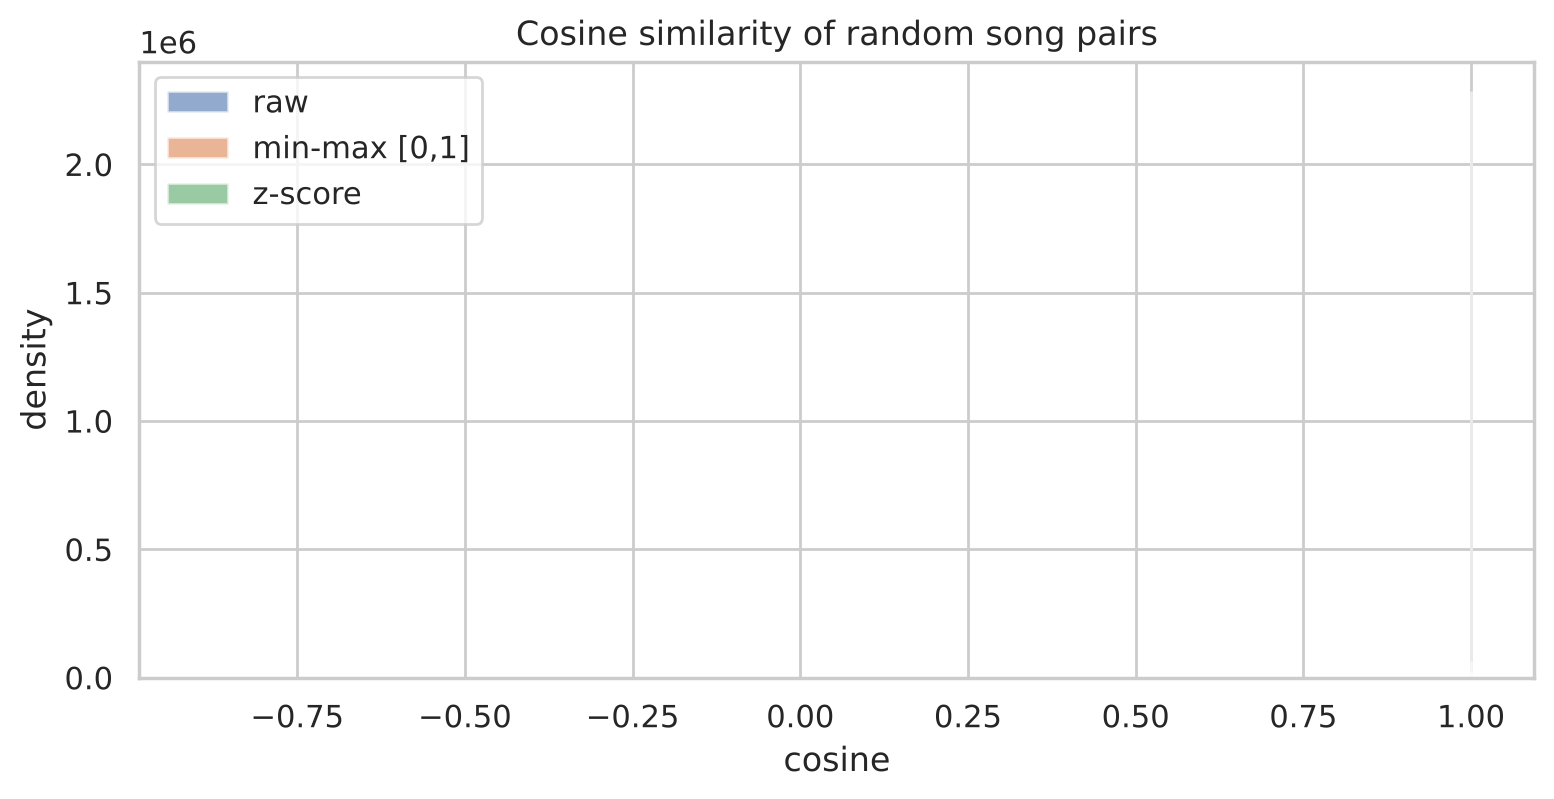

In [10]:
def random_pair_cosine(M, n=20000):
    i = RNG.integers(0, len(M), n); j = RNG.integers(0, len(M), n)
    A, B = M[i], M[j]
    return (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1) + 1e-12)

X_raw = df[AUDIO].values.astype(float)
variants = {
    "raw": X_raw,
    "min-max [0,1]": MinMaxScaler().fit_transform(X_raw),
    "z-score": StandardScaler().fit_transform(X_raw),
}
cos_results = {k: random_pair_cosine(v) for k, v in variants.items()}
print(pd.DataFrame({k: {"mean": v.mean(), "std": v.std()} for k, v in cos_results.items()}).T)

fig, ax = plt.subplots(figsize=(9, 4))
for k, v in cos_results.items():
    ax.hist(v, bins=80, alpha=0.6, label=k, density=True)
ax.set(title="Cosine similarity of random song pairs", xlabel="cosine", ylabel="density")
ax.legend(); plt.show()

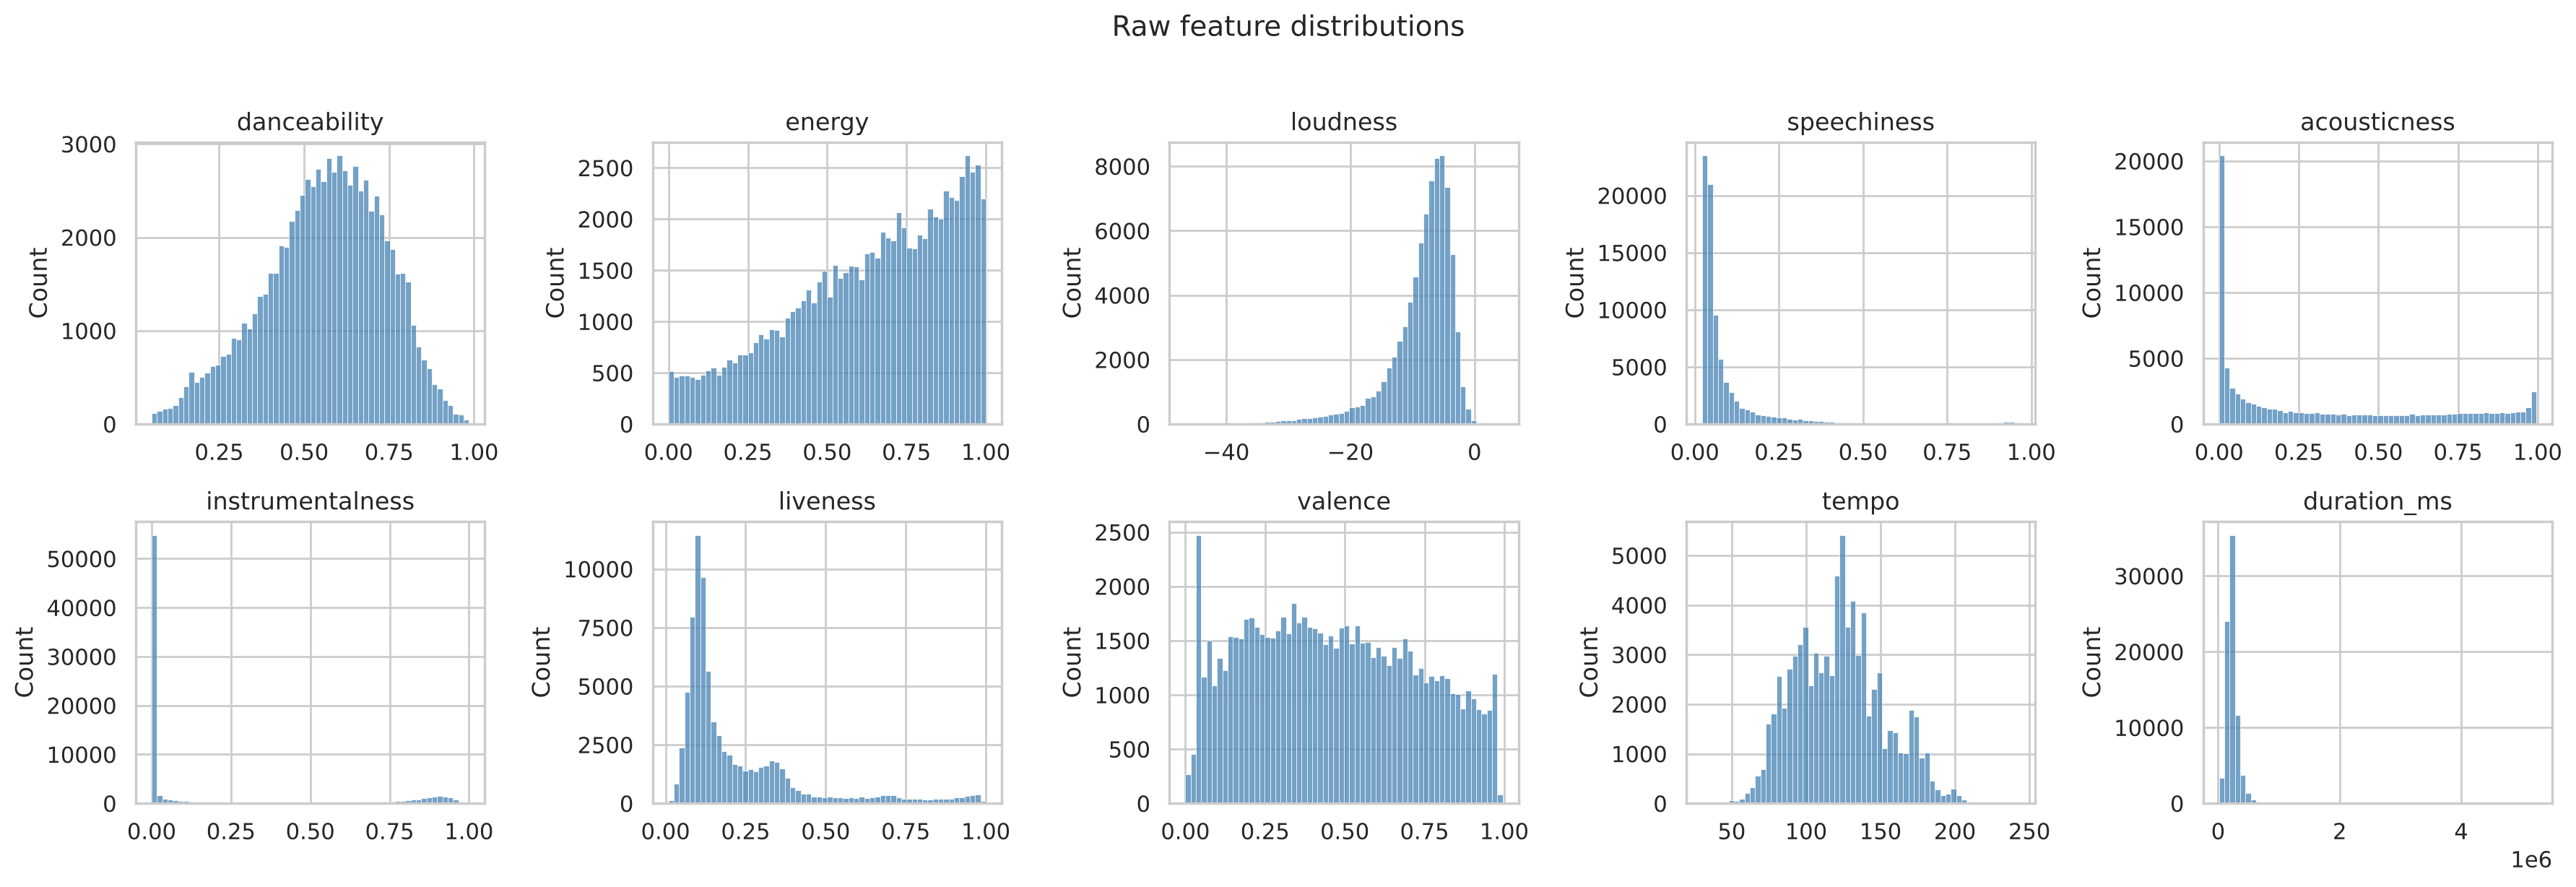

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, col in zip(axes.flat, AUDIO):
    sns.histplot(df[col], bins=60, ax=ax, color="steelblue")
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Raw feature distributions", y=1.02, fontsize=14); plt.tight_layout(); plt.show()

## 4. Skewness & distribution shape

$$\text{skew} = \frac{E[(X-\mu)^3]}{\sigma^3}$$

Z-scoring uses μ and σ, and both are dragged by outliers. One 87-minute track inflates σ for duration, so every normal song's z-score gets squashed toward 0 and the feature stops discriminating. |skew| > 1 is a red flag.

In [12]:
skew_tbl = pd.DataFrame({
    "skew": df[AUDIO].skew(),
    "kurtosis": df[AUDIO].kurt(),
    "share_near_0 (<0.05)": (df[AUDIO] < 0.05).mean(),
}).sort_values("skew", key=abs, ascending=False)
skew_tbl

,skew,kurtosis,share_near_0 (<0.05)
duration_ms,10.670,316.005,0.000
speechiness,4.477,25.373,0.509
liveness,2.034,3.878,0.023
loudness,-1.915,5.134,0.999
instrumentalness,1.465,0.368,0.714
acousticness,0.650,-1.075,0.341
energy,-0.560,-0.621,0.018
danceability,-0.360,-0.291,0.000
tempo,0.278,-0.411,0.000
valence,0.154,-1.045,0.040


Share of IQR outliers per feature:
 instrumentalness    21.27 %
speechiness         11.86 %
liveness              8.0 %
loudness             5.61 %
duration_ms          4.64 %
tempo                0.38 %
danceability         0.32 %
energy                0.0 %
acousticness          0.0 %
valence               0.0 %
dtype: str


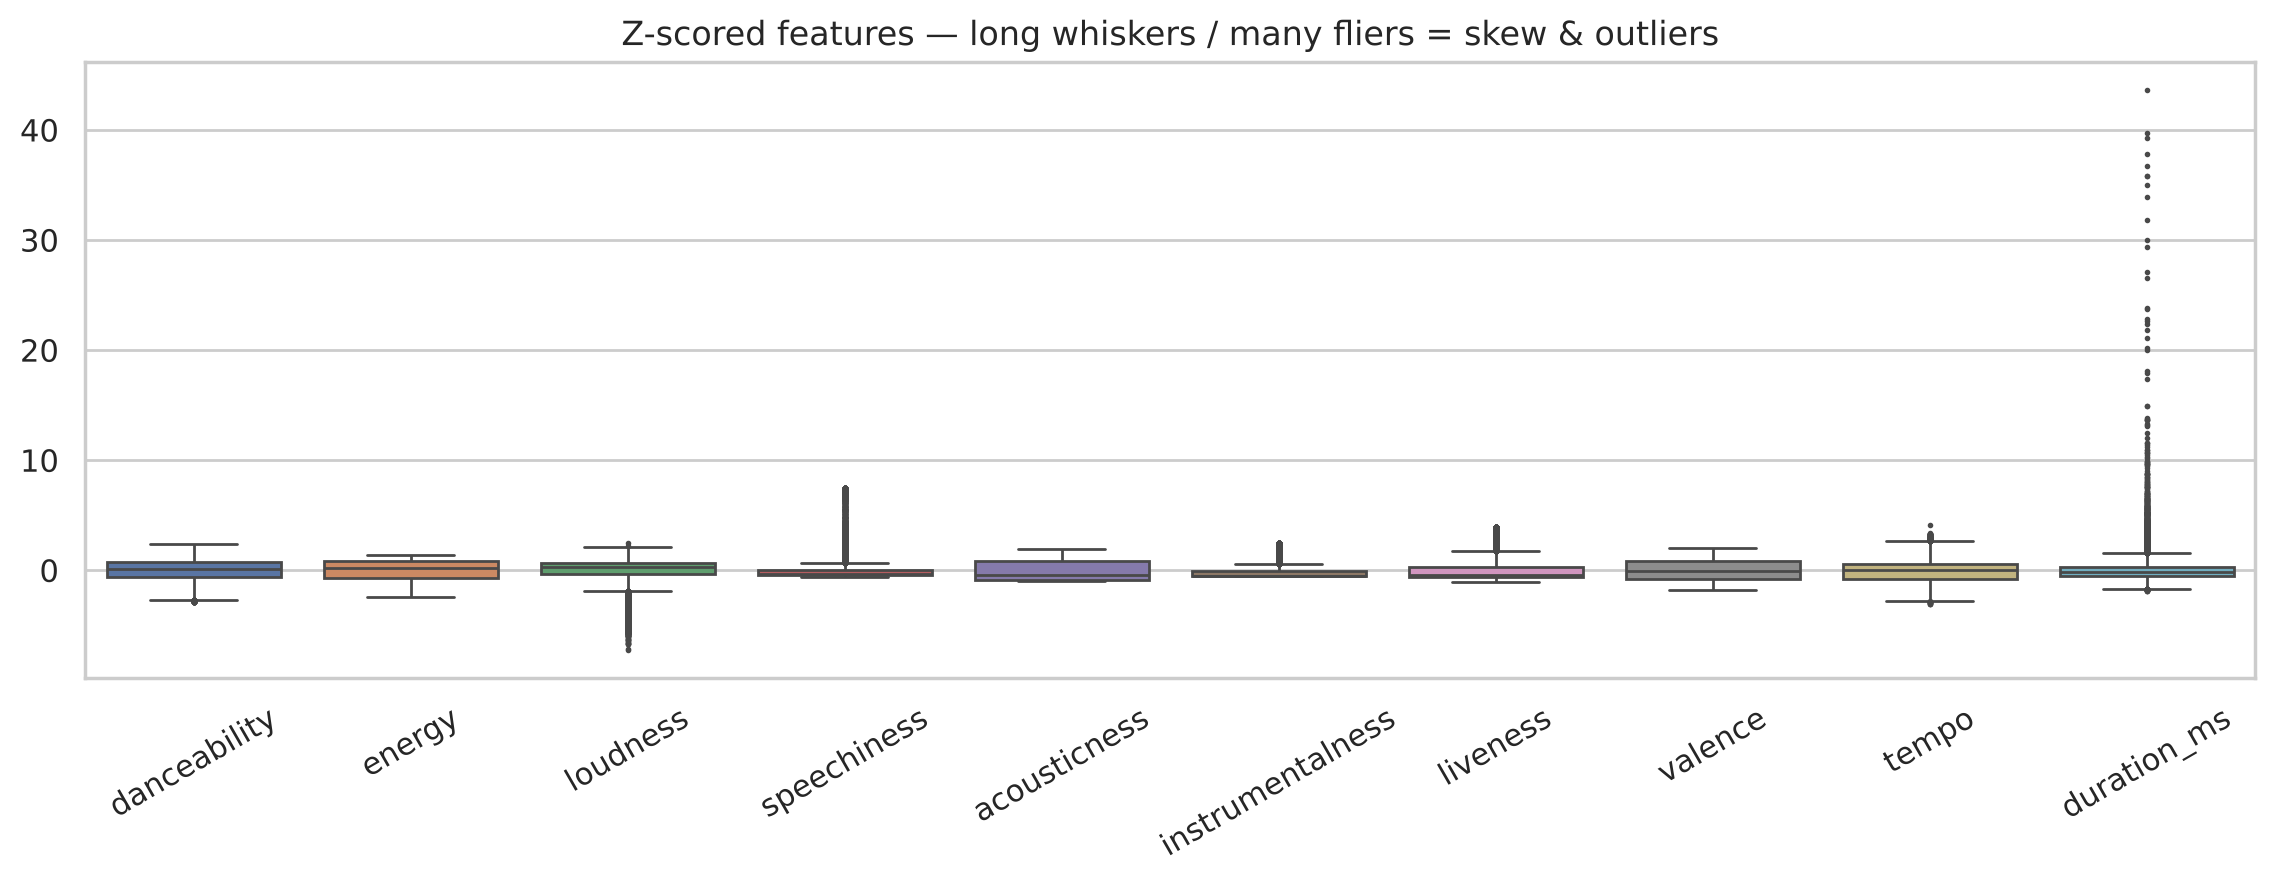

In [13]:
# Outliers by IQR rule:  x < Q1 - 1.5*IQR  or  x > Q3 + 1.5*IQR
q1, q3 = df[AUDIO].quantile(0.25), df[AUDIO].quantile(0.75)
iqr = q3 - q1
outlier_share = ((df[AUDIO] < q1 - 1.5 * iqr) | (df[AUDIO] > q3 + 1.5 * iqr)).mean().sort_values(ascending=False)
print("Share of IQR outliers per feature:\n", (outlier_share * 100).round(2).astype(str) + " %")

fig, ax = plt.subplots(figsize=(14, 4))
sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(df[AUDIO]), columns=AUDIO), ax=ax, fliersize=1)
ax.set_title("Z-scored features — long whiskers / many fliers = skew & outliers"); plt.xticks(rotation=30); plt.show()

**Bimodal features.** `instrumentalness` and `speechiness` are mostly ≈ 0 with a second cluster near 1. A 0.02 vs 0.05 difference is noise; 0.02 vs 0.9 is a real difference. Spotify's own guidance: speechiness > 0.66 ≈ spoken word, 0.33–0.66 ≈ rap/mixed; instrumentalness > 0.5 ≈ instrumental.

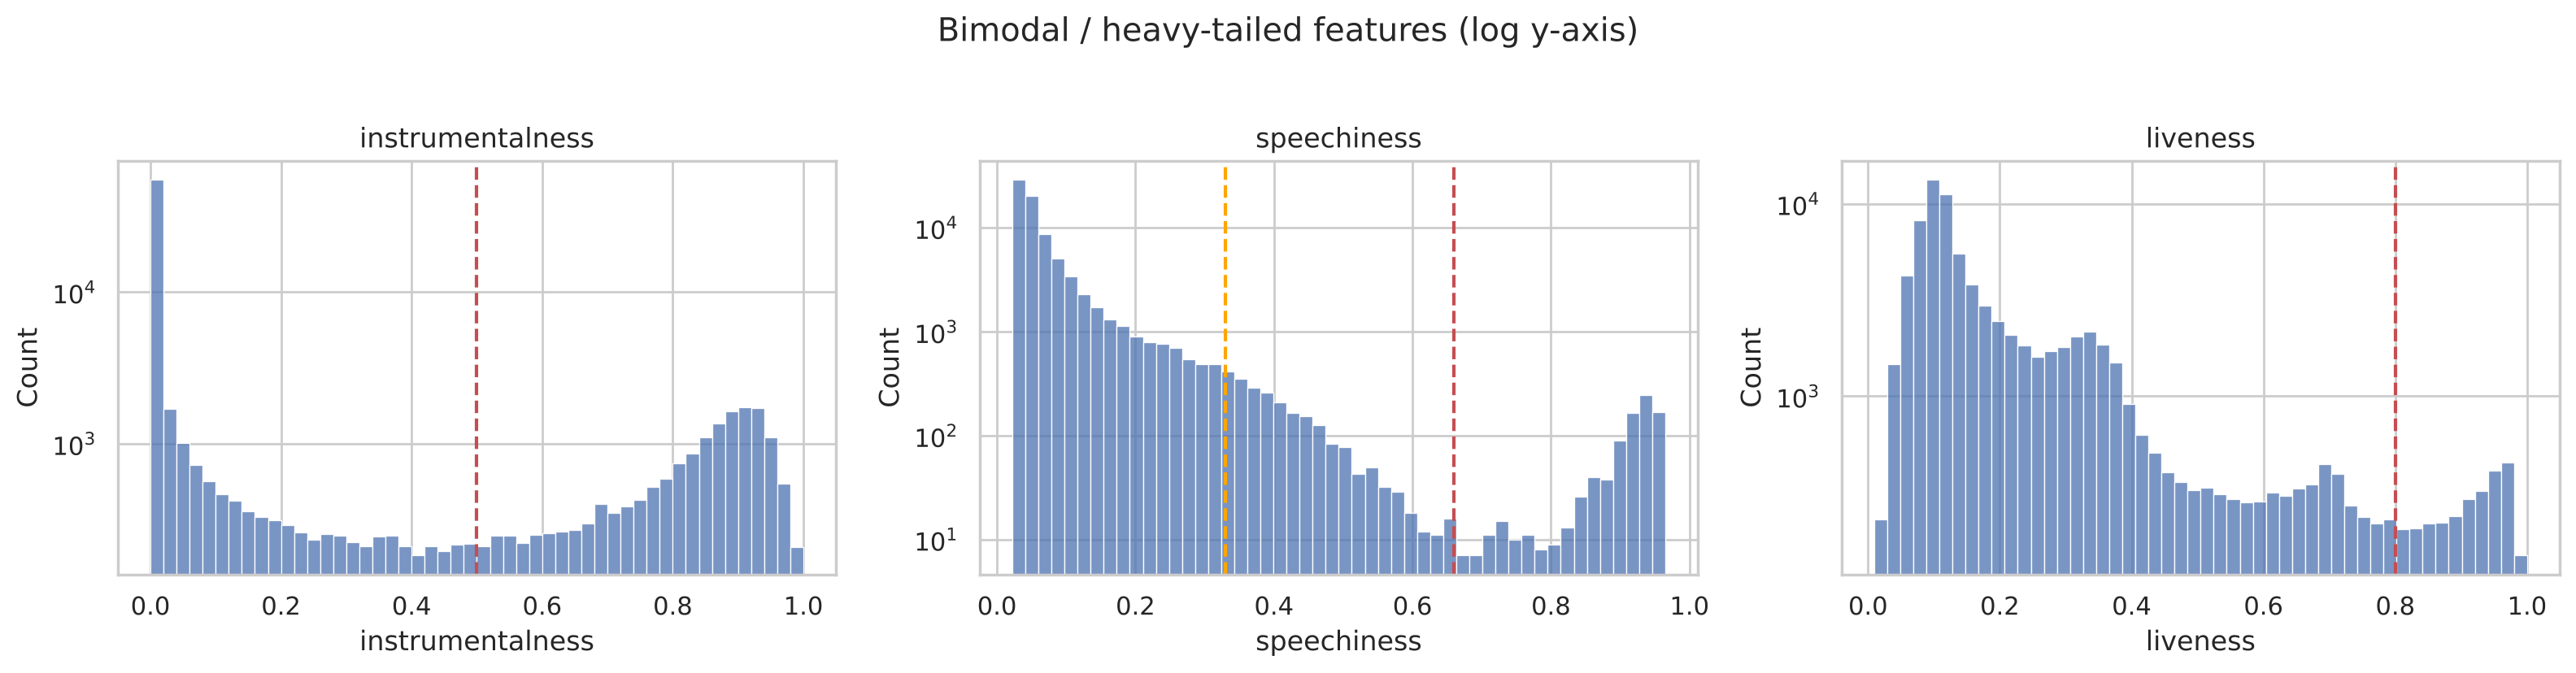

Instrumental (>0.5): 19.8%
Spoken word (>0.66): 1.1%
Likely live (>0.8):  3.4%


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["instrumentalness"], bins=50, ax=axes[0]); axes[0].axvline(0.5, c="r", ls="--"); axes[0].set_title("instrumentalness")
sns.histplot(df["speechiness"], bins=50, ax=axes[1]); axes[1].axvline(0.33, c="orange", ls="--"); axes[1].axvline(0.66, c="r", ls="--"); axes[1].set_title("speechiness")
sns.histplot(df["liveness"], bins=50, ax=axes[2]); axes[2].axvline(0.8, c="r", ls="--"); axes[2].set_title("liveness")
for ax in axes: ax.set_yscale("log")
plt.suptitle("Bimodal / heavy-tailed features (log y-axis)", y=1.03); plt.tight_layout(); plt.show()

print(f"Instrumental (>0.5): {(df.instrumentalness > 0.5).mean():.1%}")
print(f"Spoken word (>0.66): {(df.speechiness > 0.66).mean():.1%}")
print(f"Likely live (>0.8):  {(df.liveness > 0.8).mean():.1%}")

**Transformations:**
- `duration_ms` → convert to minutes, clip at the 1st–99th percentile, then $\log(1+x)$
- `speechiness`, `liveness` → $\log(1+x)$ to compress the tail, plus a binary flag
- `instrumentalness` → binary flag (> 0.5) plus the clipped value
- `loudness` → clip at the 1st percentile (left tail)

             skew before  skew after
duration          10.670      -0.017
speechiness        4.477       2.210
liveness           2.034       1.030
loudness          -1.915      -1.656


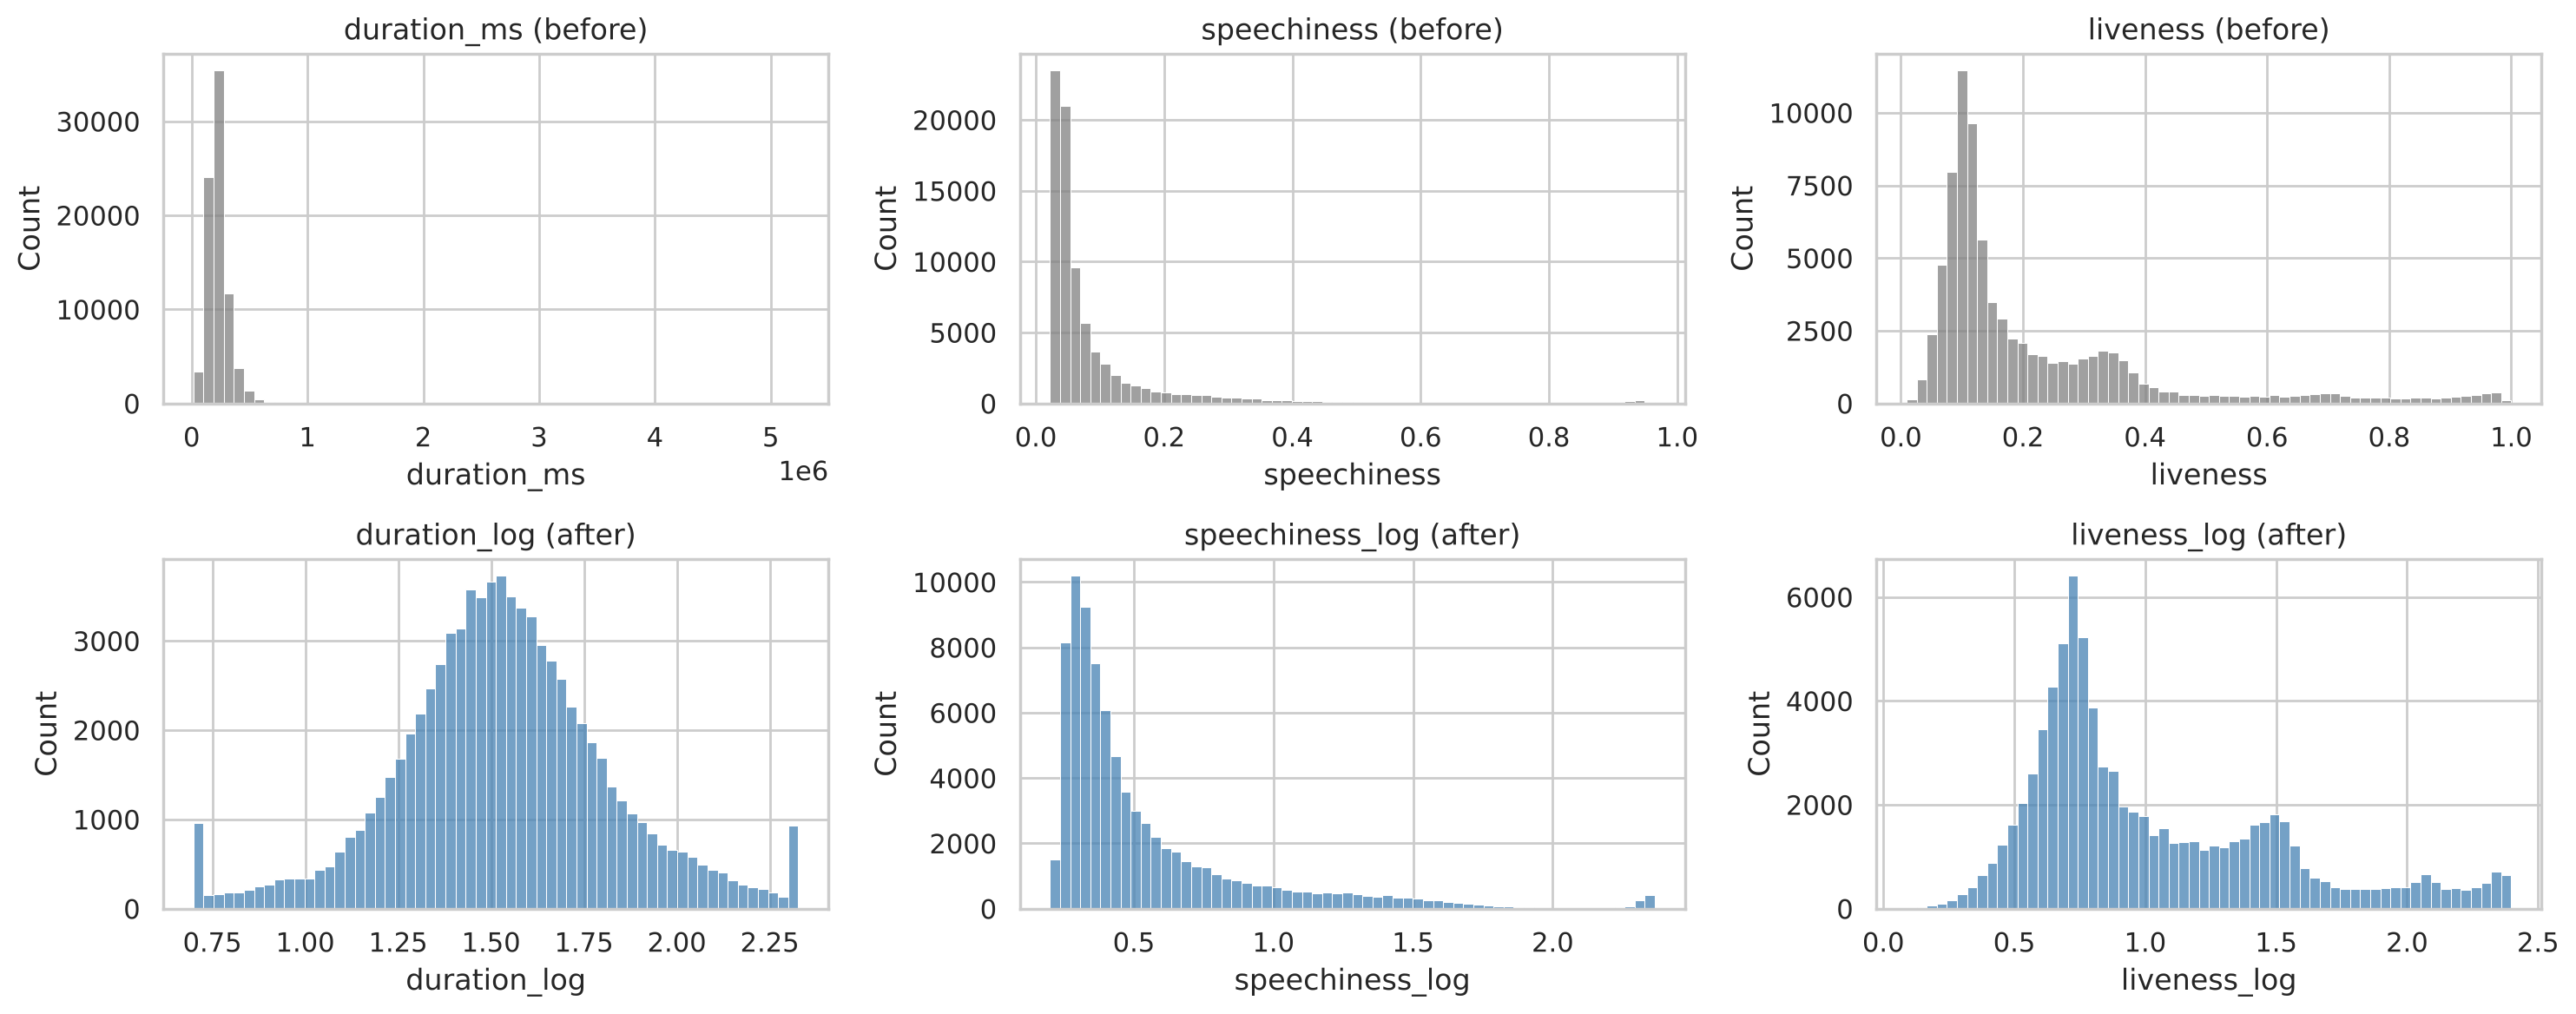

In [15]:
T = pd.DataFrame(index=df.index)
dur_min = (df["duration_ms"] / 60000).clip(*df["duration_ms"].div(60000).quantile([0.01, 0.99]))
T["duration_log"]     = np.log1p(dur_min)
T["speechiness_log"]  = np.log1p(df["speechiness"] * 10)    # *10 spreads values near 0 before the log
T["liveness_log"]     = np.log1p(df["liveness"] * 10)
T["instrumentalness"] = df["instrumentalness"]
T["is_instrumental"]  = (df["instrumentalness"] > 0.5).astype(int)
T["is_spoken"]        = (df["speechiness"] > 0.66).astype(int)
T["loudness"]         = df["loudness"].clip(lower=df["loudness"].quantile(0.01))
for c in ["danceability", "energy", "acousticness", "valence", "tempo"]:
    T[c] = df[c]

before = df[["duration_ms", "speechiness", "liveness", "loudness"]].skew()
after = T[["duration_log", "speechiness_log", "liveness_log", "loudness"]].skew()
print(pd.DataFrame({"skew before": before.values, "skew after": after.values},
                   index=["duration", "speechiness", "liveness", "loudness"]))

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for k, (b, a) in enumerate([("duration_ms", "duration_log"), ("speechiness", "speechiness_log"), ("liveness", "liveness_log")]):
    sns.histplot(df[b], bins=60, ax=axes[0, k], color="grey"); axes[0, k].set_title(f"{b} (before)")
    sns.histplot(T[a], bins=60, ax=axes[1, k], color="steelblue"); axes[1, k].set_title(f"{a} (after)")
plt.tight_layout(); plt.show()

## 5. Correlation analysis & PCA

$$r_{XY} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i-\bar{x})^2}\sqrt{\sum (y_i-\bar{y})^2}}$$

Strongly correlated features measure the same thing. Each adds its own squared term to the distance, so that underlying property gets counted several times.

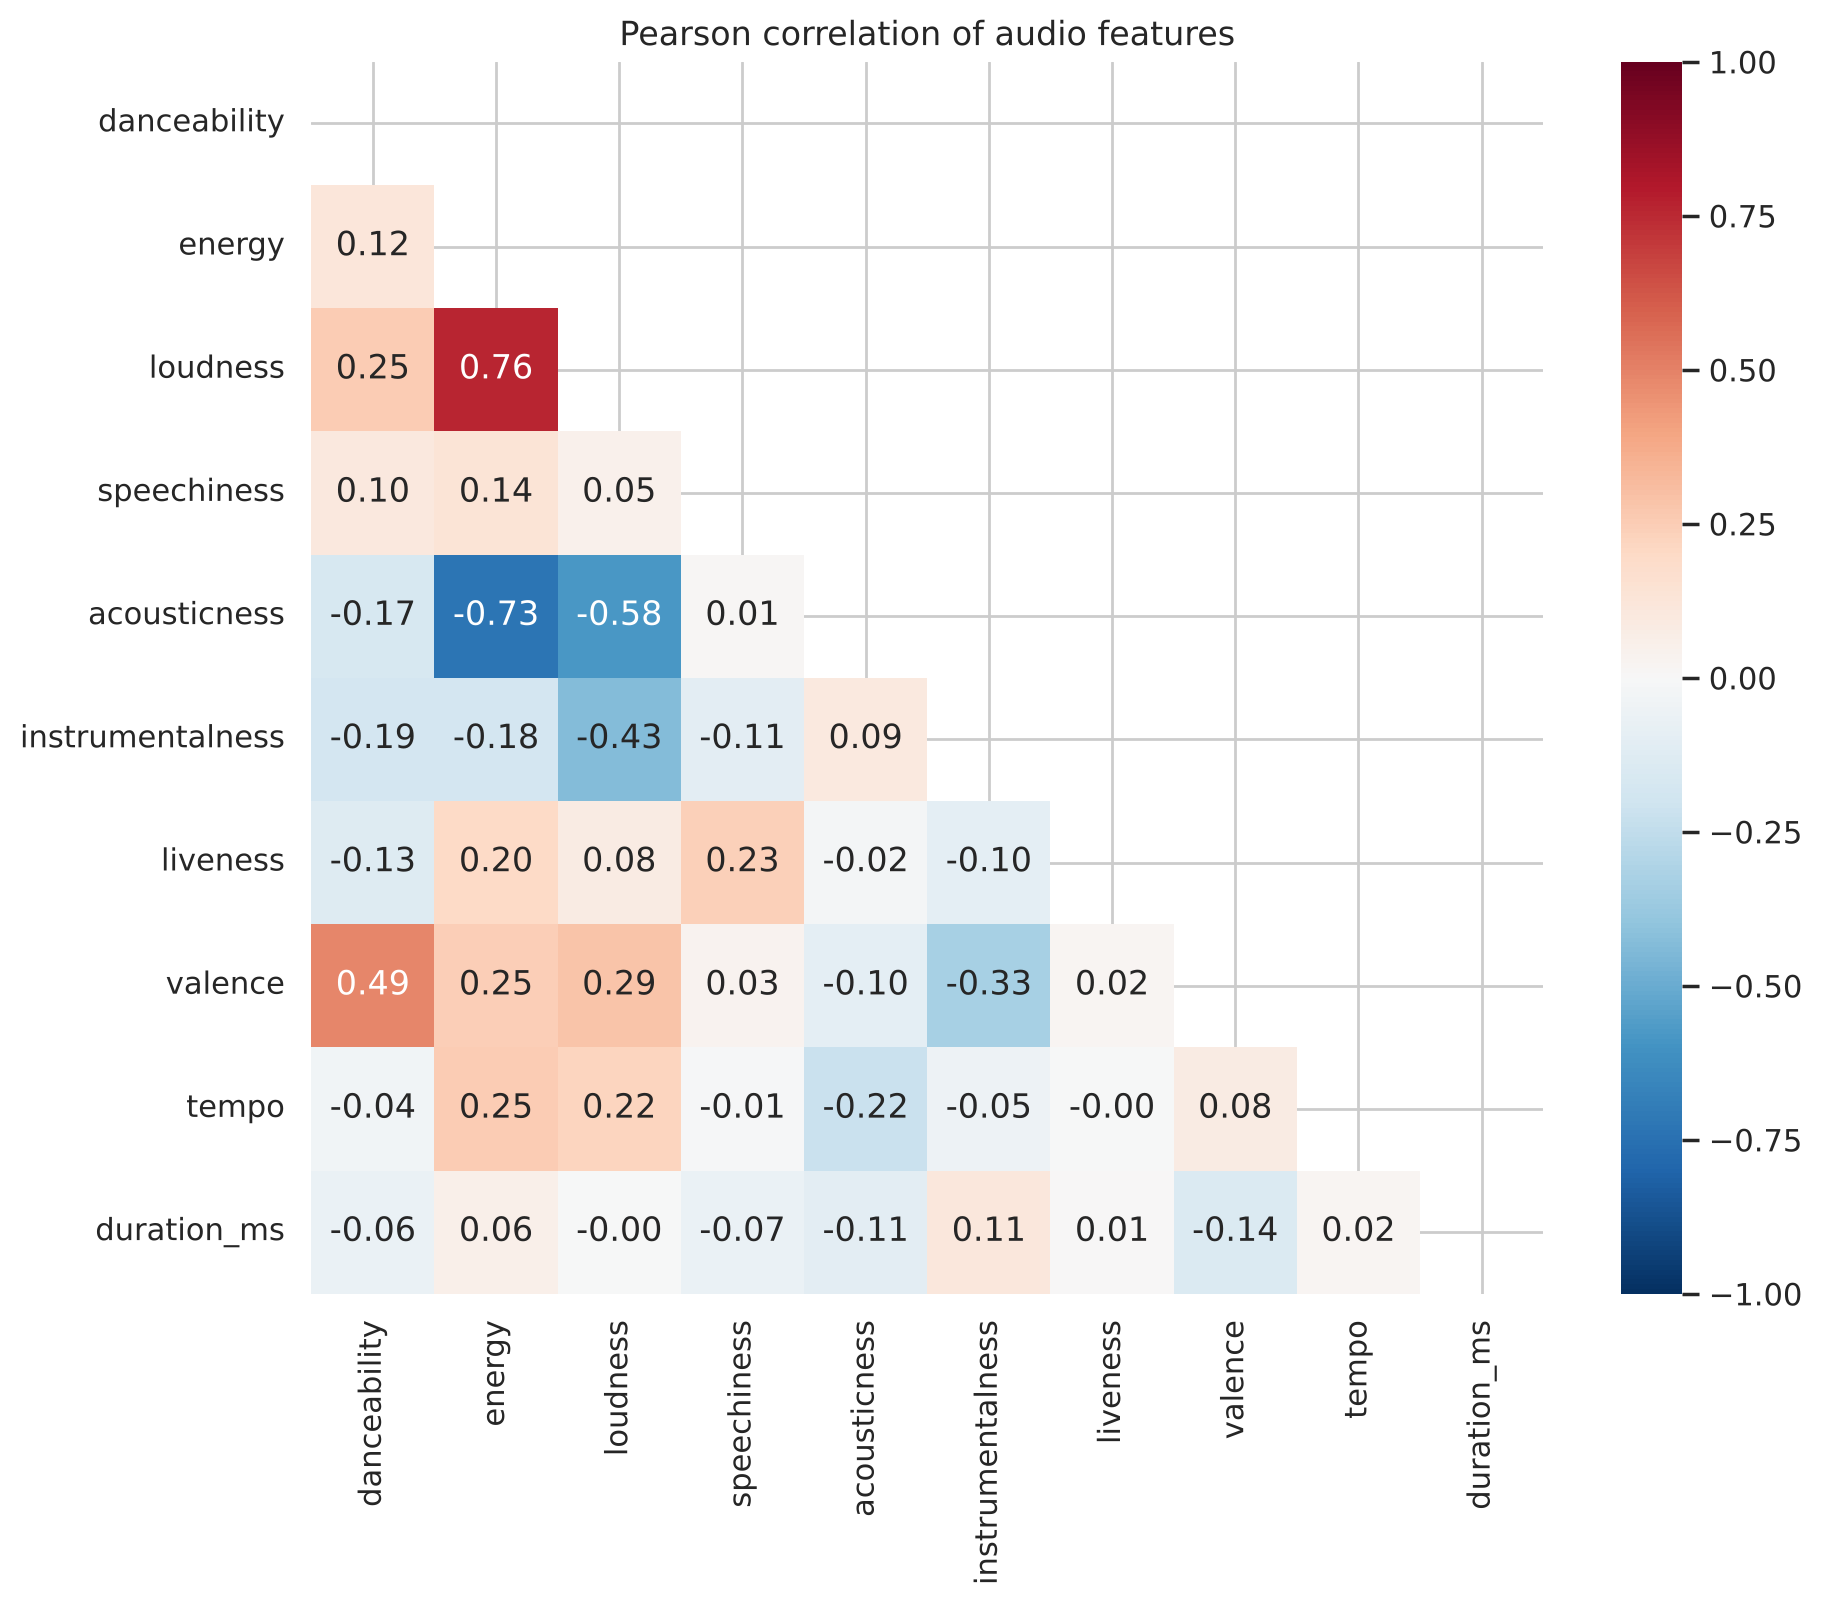

Pairs with |r| > 0.4:
         level_0      level_1      r
        loudness       energy  0.761
    acousticness       energy -0.733
    acousticness     loudness -0.584
         valence danceability  0.488
instrumentalness     loudness -0.434


In [16]:
corr = df[AUDIO].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Pearson correlation of audio features"); plt.show()

pairs = (corr.where(~mask).stack().rename("r").reset_index()
             .assign(abs_r=lambda d: d.r.abs()).sort_values("abs_r", ascending=False))
print("Pairs with |r| > 0.4:")
print(pairs[pairs.abs_r > 0.4][["level_0", "level_1", "r"]].to_string(index=False))

In [17]:
# Spearman (rank) correlation is robust to the skew found in section 4
spearman = df[AUDIO].corr(method="spearman")
diff = (spearman - corr).abs()
print("Biggest Pearson vs Spearman gaps (non-linear / outlier-driven relationships):")
print(diff.where(~mask).stack().sort_values(ascending=False).head(5))

Biggest Pearson vs Spearman gaps (non-linear / outlier-driven relationships):
acousticness      speechiness    0.226
speechiness       energy         0.210
instrumentalness  acousticness   0.187
speechiness       loudness       0.159
loudness          danceability   0.157
dtype: float64


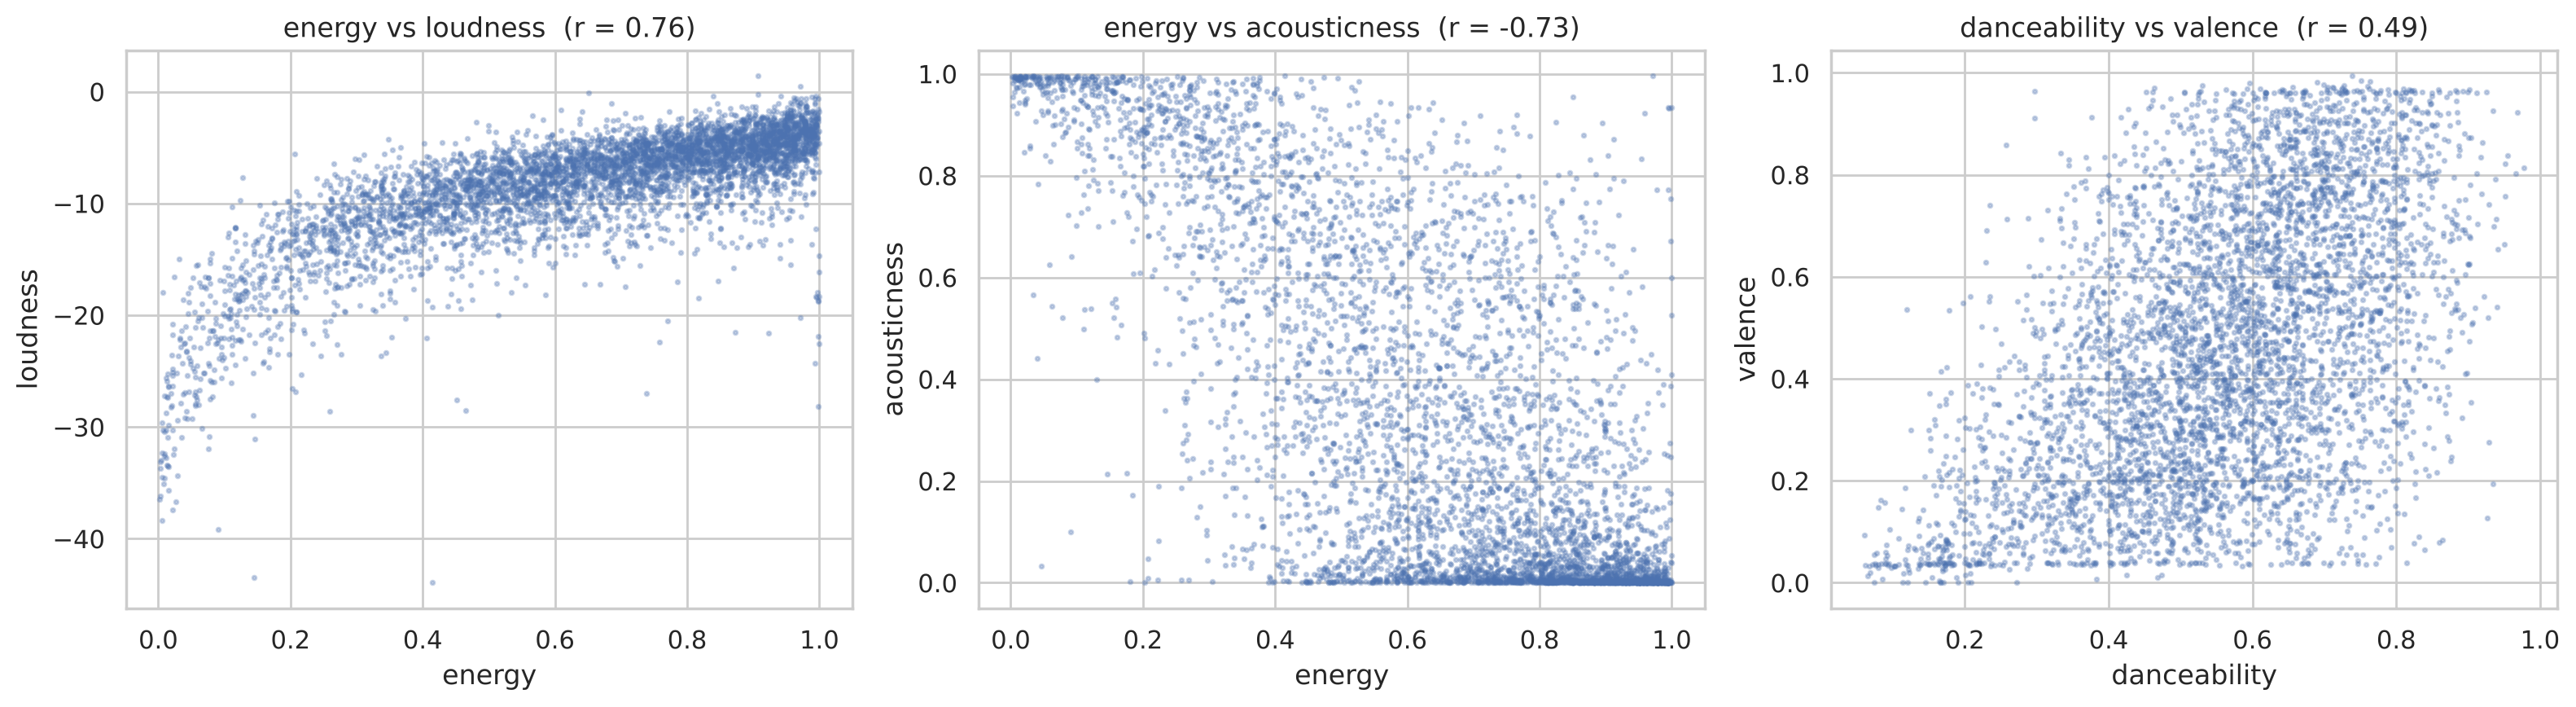

In [18]:
sample = df.sample(5000, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (x, y) in zip(axes, [("energy", "loudness"), ("energy", "acousticness"), ("danceability", "valence")]):
    ax.scatter(sample[x], sample[y], s=3, alpha=0.3)
    ax.set(xlabel=x, ylabel=y, title=f"{x} vs {y}  (r = {corr.loc[x, y]:.2f})")
plt.tight_layout(); plt.show()

**PCA** rotates the standardized data onto uncorrelated axes. The principal components are eigenvectors of the covariance matrix Σ:

$$\Sigma \mathbf{v} = \lambda \mathbf{v}, \qquad \text{explained variance of PC}_i = \frac{\lambda_i}{\sum_j \lambda_j}$$

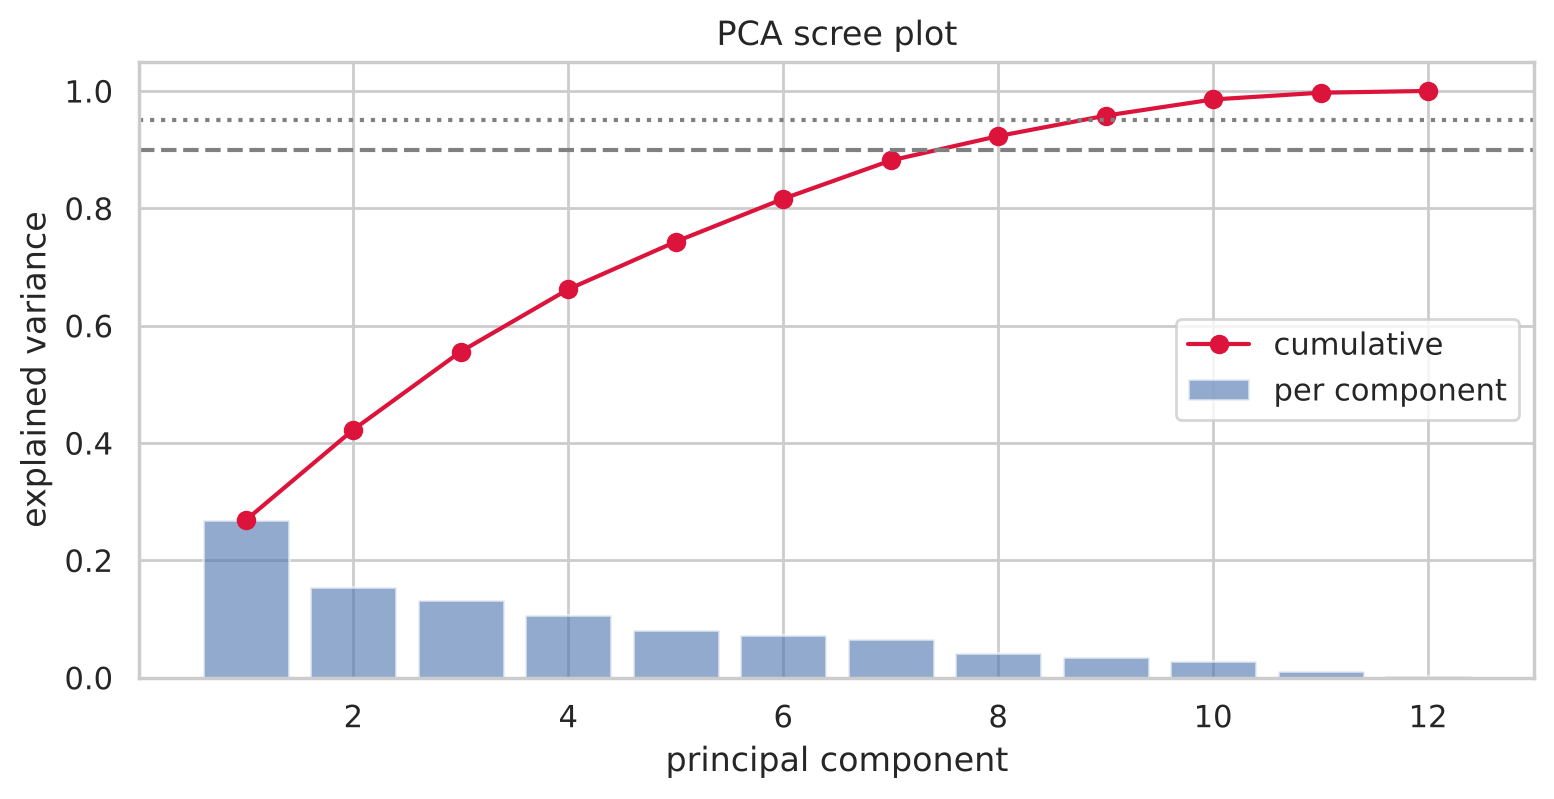

Components for 90% variance: 8 of 12
Components for 95% variance: 9 of 12


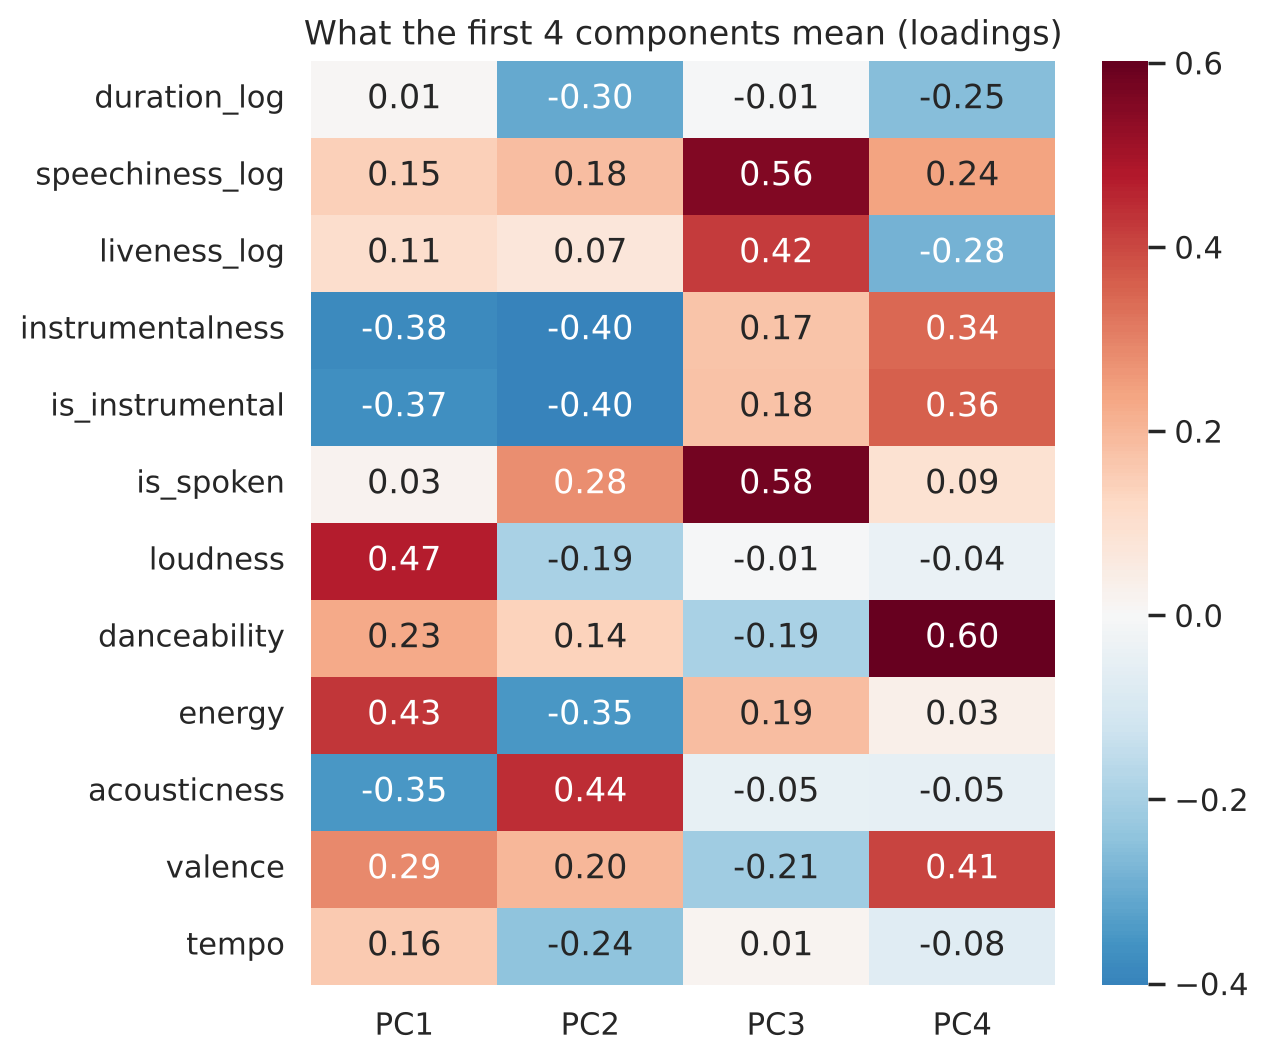

In [19]:
Z_T = StandardScaler().fit_transform(T)
pca = PCA().fit(Z_T)
cum = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, alpha=0.6, label="per component")
ax.plot(range(1, len(cum) + 1), cum, "o-", c="crimson", label="cumulative")
ax.axhline(0.90, ls="--", c="grey"); ax.axhline(0.95, ls=":", c="grey")
ax.set(xlabel="principal component", ylabel="explained variance", title="PCA scree plot"); ax.legend(); plt.show()

print("Components for 90% variance:", int(np.argmax(cum >= 0.90)) + 1, "of", len(cum))
print("Components for 95% variance:", int(np.argmax(cum >= 0.95)) + 1, "of", len(cum))

loadings = pd.DataFrame(pca.components_[:4].T, index=T.columns, columns=[f"PC{i}" for i in range(1, 5)])
plt.figure(figsize=(6, 6)); sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("What the first 4 components mean (loadings)"); plt.show()

**Mahalanobis distance** corrects for correlation directly, without dropping features:

$$d_M(\mathbf{x},\mathbf{y}) = \sqrt{(\mathbf{x}-\mathbf{y})^\top \Sigma^{-1} (\mathbf{x}-\mathbf{y})}$$

Equivalent trick: *whiten* the data ($\mathbf{x}' = \Sigma^{-1/2}\mathbf{x}$, i.e. PCA with `whiten=True`), then plain Euclidean distance on $\mathbf{x}'$ equals Mahalanobis on $\mathbf{x}$.

In [20]:
cov_inv = np.linalg.inv(np.cov(Z_T, rowvar=False))
def mahalanobis(u, v):
    d = u - v
    return float(np.sqrt(d @ cov_inv @ d))

W = PCA(whiten=True).fit_transform(Z_T)
i, j = 0, 1
print(f"Euclidean (z-scored):       {np.linalg.norm(Z_T[i] - Z_T[j]):.4f}")
print(f"Mahalanobis (z-scored):     {mahalanobis(Z_T[i], Z_T[j]):.4f}")
print(f"Euclidean on whitened data: {np.linalg.norm(W[i] - W[j]):.4f}   <- same as Mahalanobis")

Euclidean (z-scored):       2.0436
Mahalanobis (z-scored):     2.7928
Euclidean on whitened data: 2.7928   <- same as Mahalanobis


## 6. Feature weighting via ANOVA F-scores

With 114 genres you have a free "ground truth" for similarity. ANOVA asks which features differ most **between** genres relative to **within** genres:

$$F = \frac{\sum_g n_g(\bar{x}_g - \bar{x})^2 / (G-1)}{\sum_g \sum_{i\in g}(x_i - \bar{x}_g)^2 / (N-G)}$$

High F = the feature separates musical styles → give it more weight in the distance:

$$d_w(\mathbf{x},\mathbf{y}) = \sqrt{\sum_k w_k (x_k - y_k)^2}, \qquad w_k \propto F_k$$

(Uses the raw rows, where each row has a single genre label.)

In [21]:
raw_ok = raw.dropna(subset=["track_name"]).query("tempo > 0")
F, p = f_classif(raw_ok[AUDIO], raw_ok["track_genre"])
f_tbl = pd.DataFrame({"F": F, "p_value": p}, index=AUDIO).sort_values("F", ascending=False)

# eta^2 = SS_between / SS_total : share of a feature's variance explained by genre (0..1)
def eta_squared(x, g):
    grand = x.mean()
    ss_between = x.groupby(g).apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    return ss_between / ((x - grand) ** 2).sum()
f_tbl["eta_sq"] = [eta_squared(raw_ok[c], raw_ok["track_genre"]) for c in f_tbl.index]
f_tbl["weight (F / max F)"] = f_tbl["F"] / f_tbl["F"].max()
f_tbl

,F,p_value,eta_sq,weight (F / max F)
acousticness,963.223,0.000,0.489,1.000
energy,837.197,0.000,0.454,0.869
instrumentalness,828.542,0.000,0.452,0.860
loudness,817.801,0.000,0.448,0.849
speechiness,796.100,0.000,0.442,0.826
danceability,694.469,0.000,0.408,0.721
valence,434.495,0.000,0.302,0.451
duration_ms,202.109,0.000,0.167,0.210
liveness,178.705,0.000,0.151,0.186
tempo,84.632,0.000,0.078,0.088


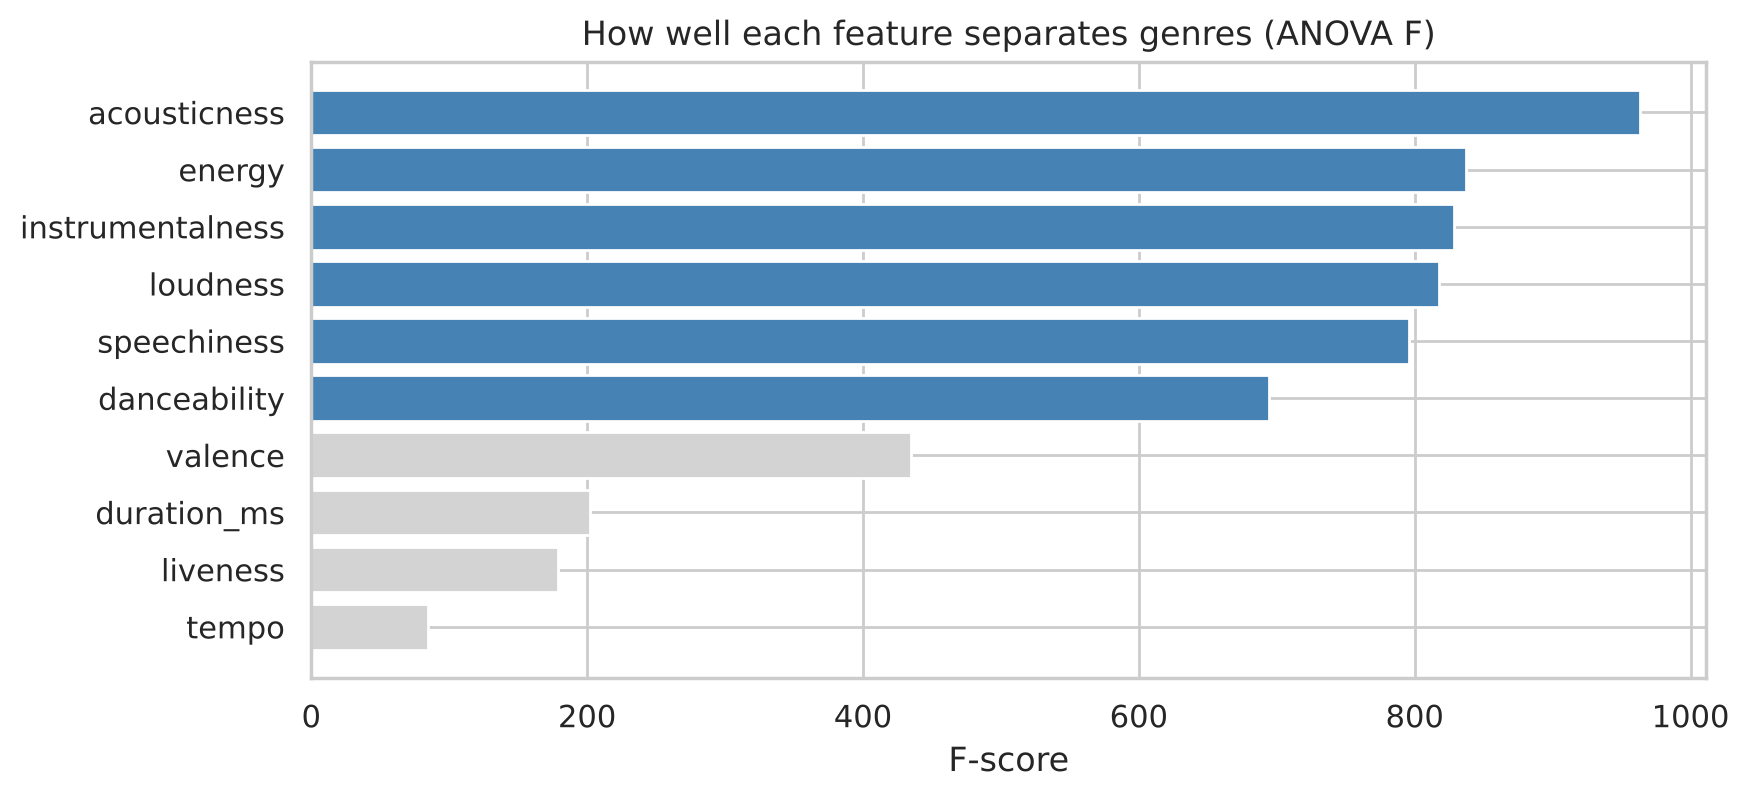

In [22]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["steelblue" if i < 6 else "lightgrey" for i in range(len(f_tbl))]
ax.barh(f_tbl.index[::-1], f_tbl["F"][::-1], color=colors[::-1])
ax.set(title="How well each feature separates genres (ANOVA F)", xlabel="F-score"); plt.show()

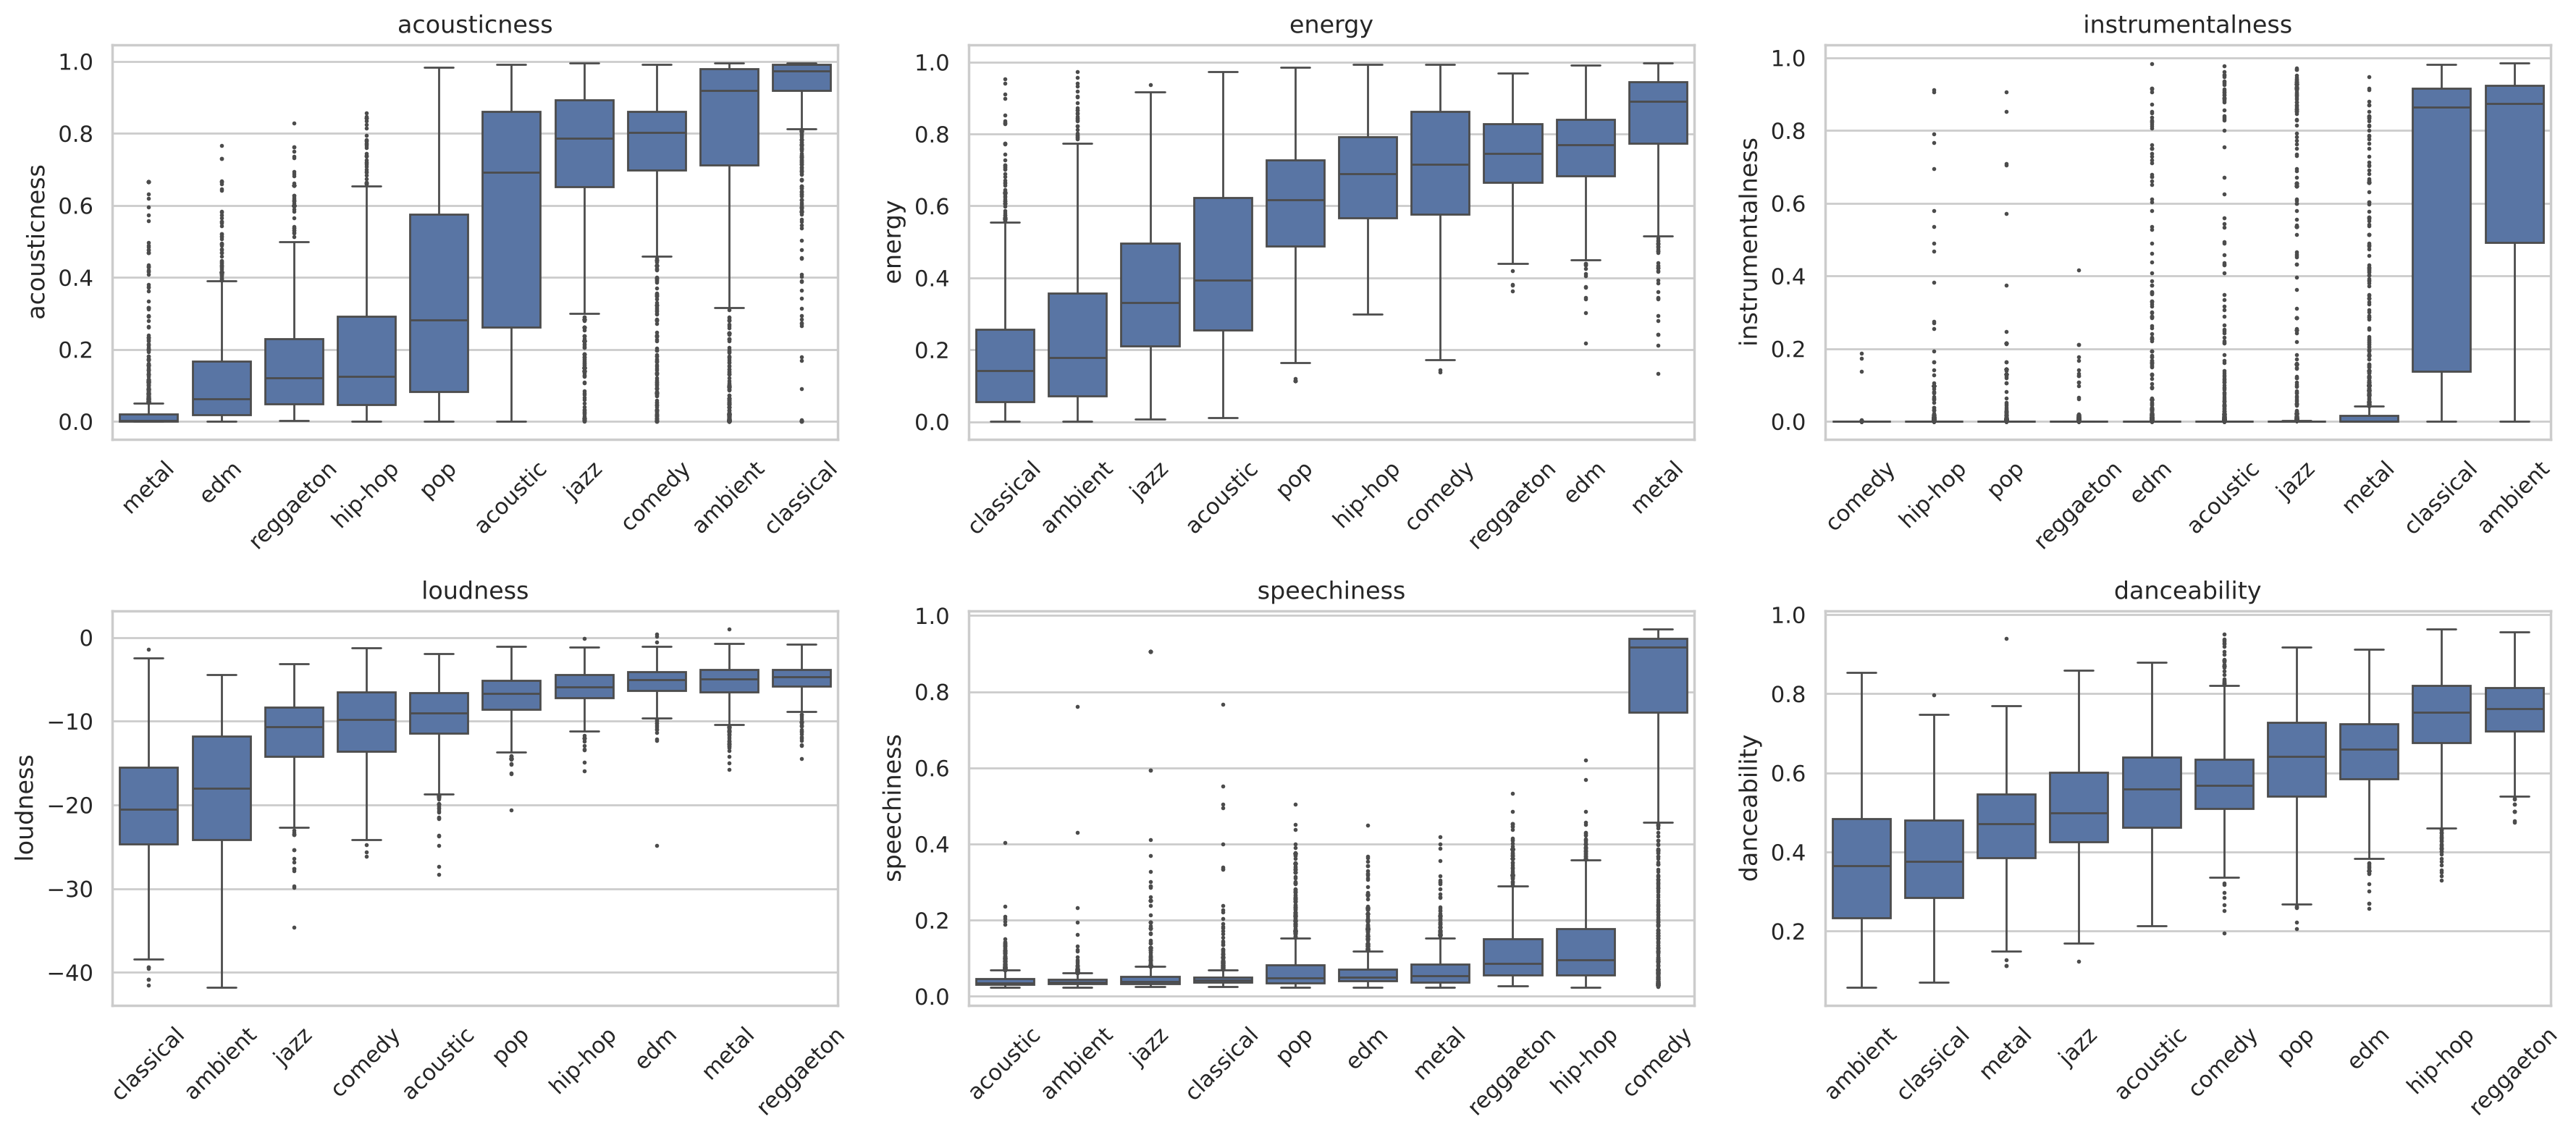

In [23]:
# Box plots for a readable subset of contrasting genres
show = ["classical", "metal", "hip-hop", "edm", "acoustic", "jazz", "pop", "ambient", "reggaeton", "comedy"]
show = [g for g in show if g in raw_ok["track_genre"].unique()]
sub = raw_ok[raw_ok["track_genre"].isin(show)]

top_feats = f_tbl.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.flat, top_feats):
    order = sub.groupby("track_genre")[col].median().sort_values().index
    sns.boxplot(data=sub, x="track_genre", y=col, order=order, ax=ax, fliersize=1)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

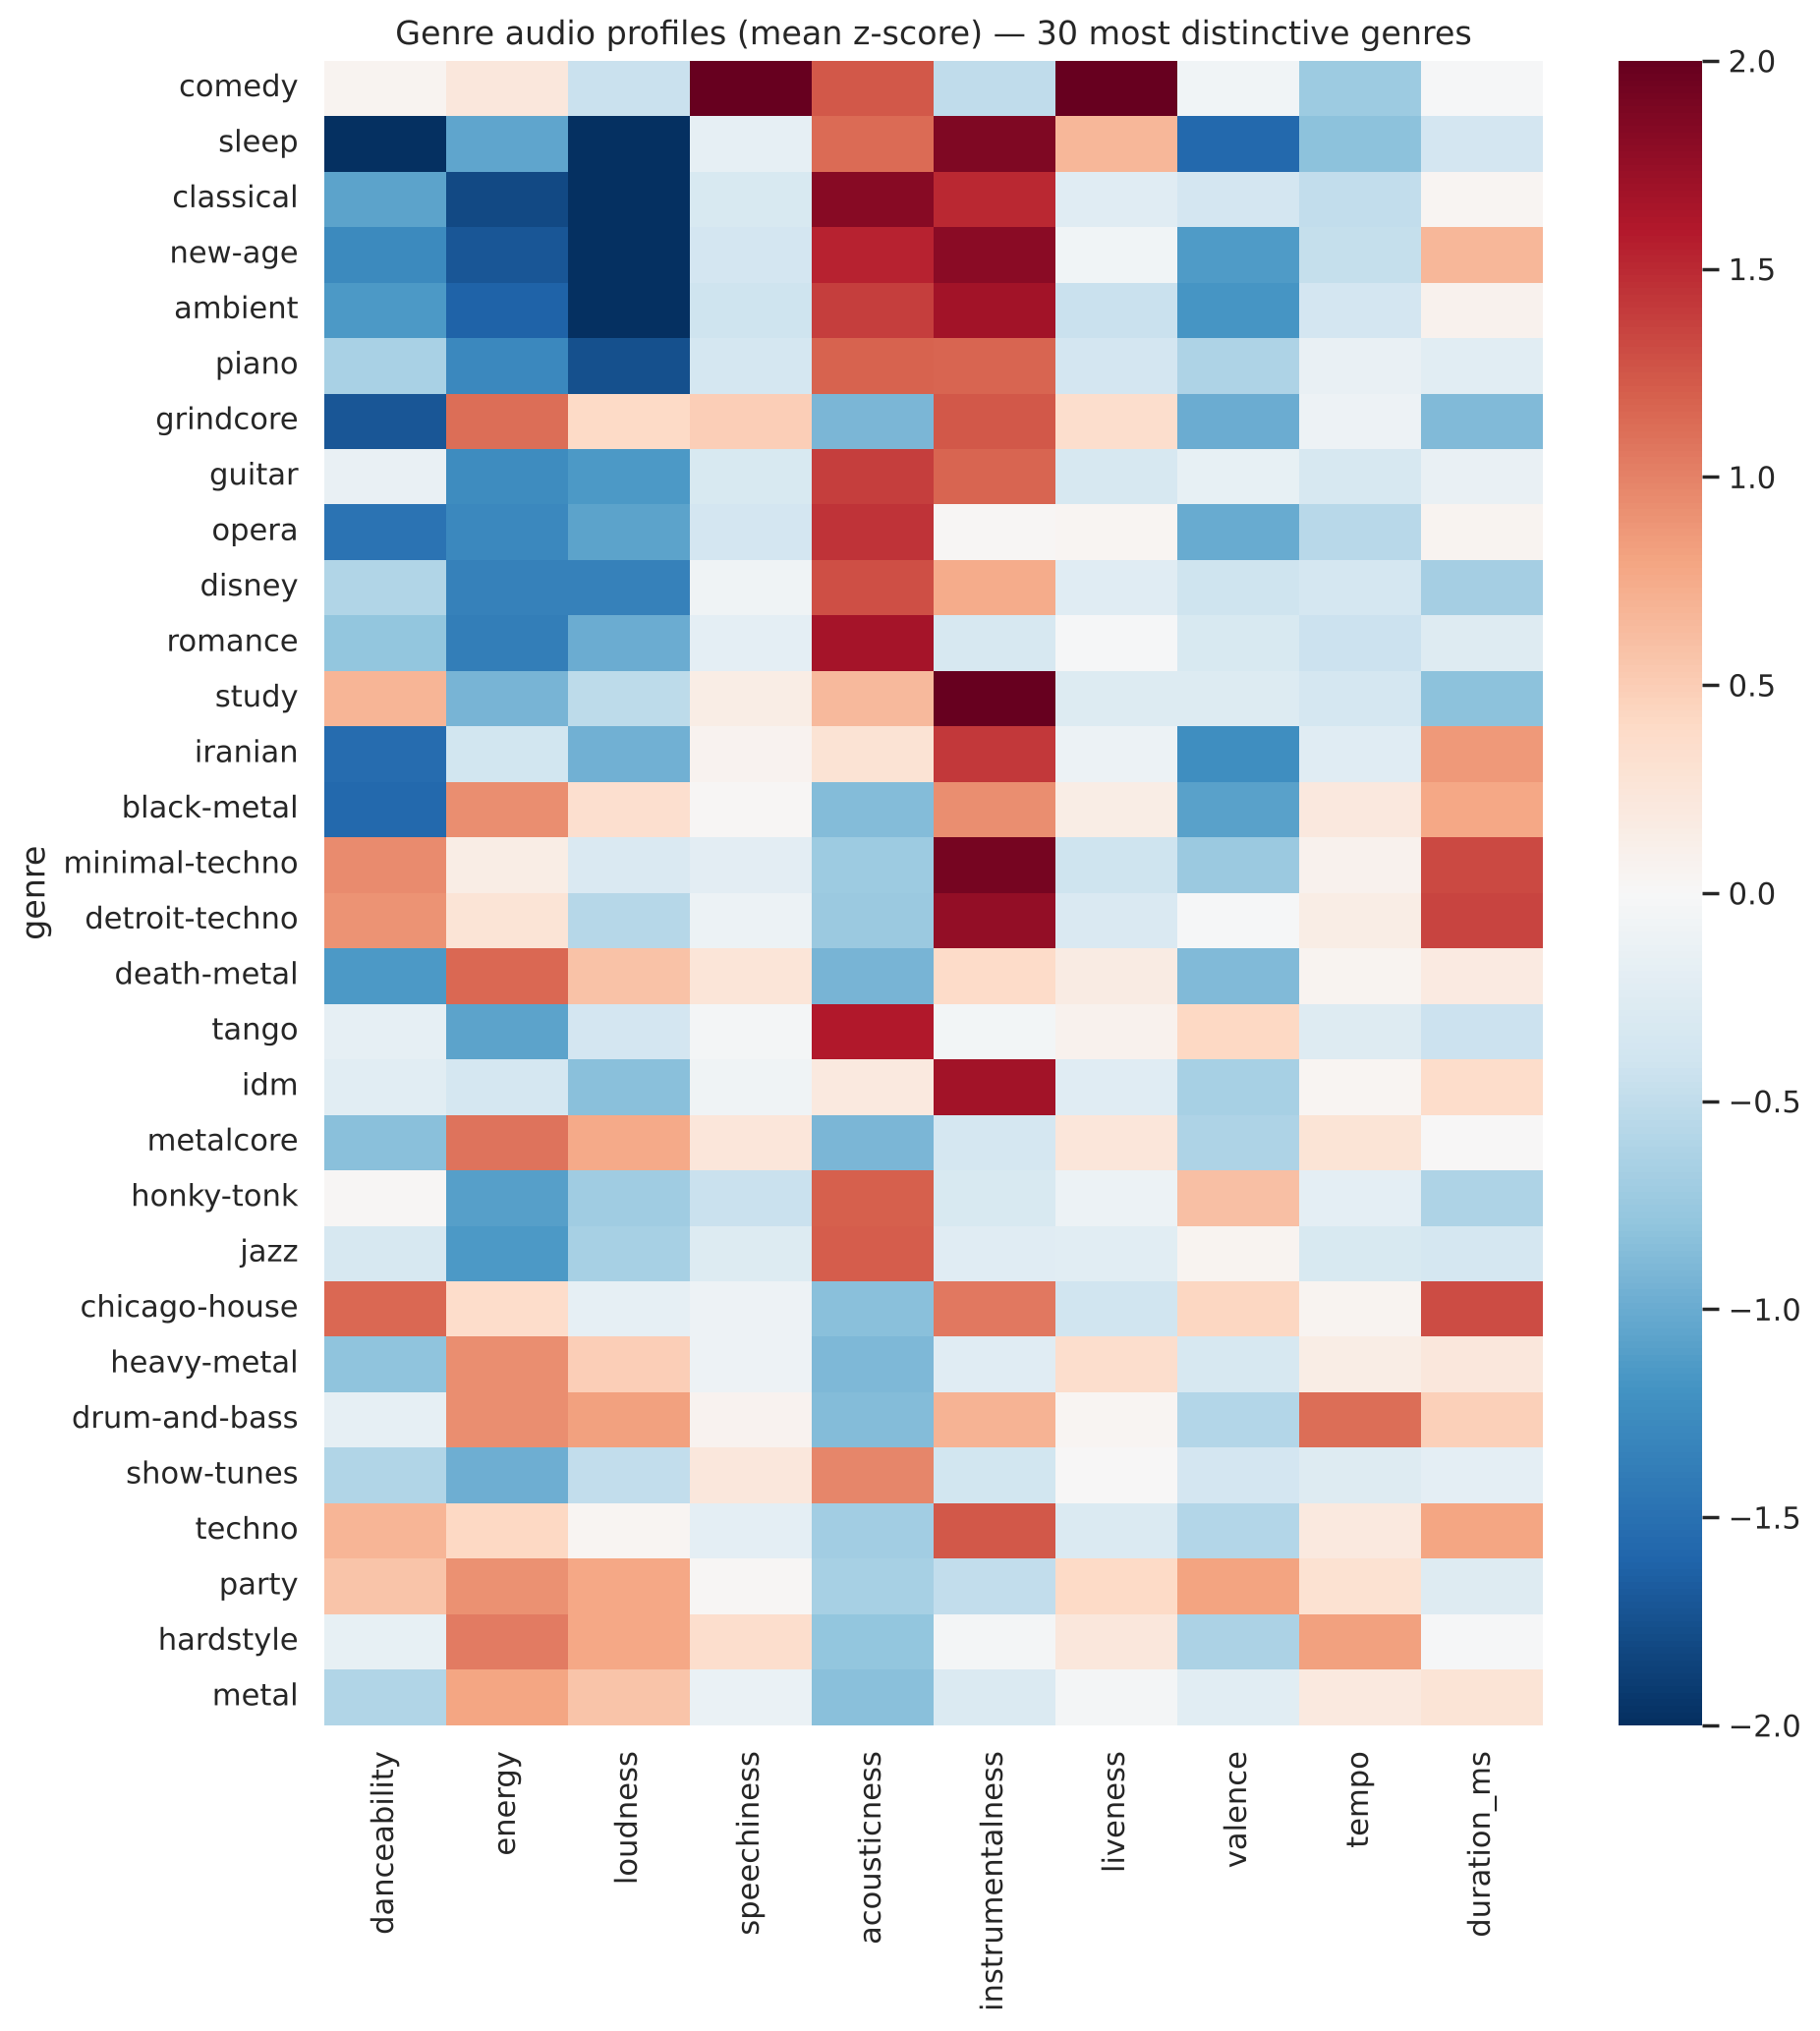

In [24]:
# Genre x feature profile: mean z-score of each feature per genre
zg = raw_ok[AUDIO].apply(stats.zscore)
zg["genre"] = raw_ok["track_genre"].values
profile = zg.groupby("genre").mean()
top_var = profile.loc[:, top_feats].var(axis=1).sort_values(ascending=False).index[:30]

plt.figure(figsize=(10, 11))
sns.heatmap(profile.loc[top_var, AUDIO], cmap="RdBu_r", center=0, vmin=-2, vmax=2)
plt.title("Genre audio profiles (mean z-score) — 30 most distinctive genres"); plt.show()

## 7. Categorical & circular features

**`key` is circular.** Treated as a number, key 11 (B) and key 0 (C) look maximally far apart (|11 − 0| = 11) but they're adjacent. Put keys on a circle:

$$k \;\rightarrow\; \left(\sin\tfrac{2\pi k}{12},\; \cos\tfrac{2\pi k}{12}\right)$$

Better musically: first map to the **circle of fifths**, $k' = 7k \bmod 12$, so harmonically related keys (C–G–D…) end up neighbours.

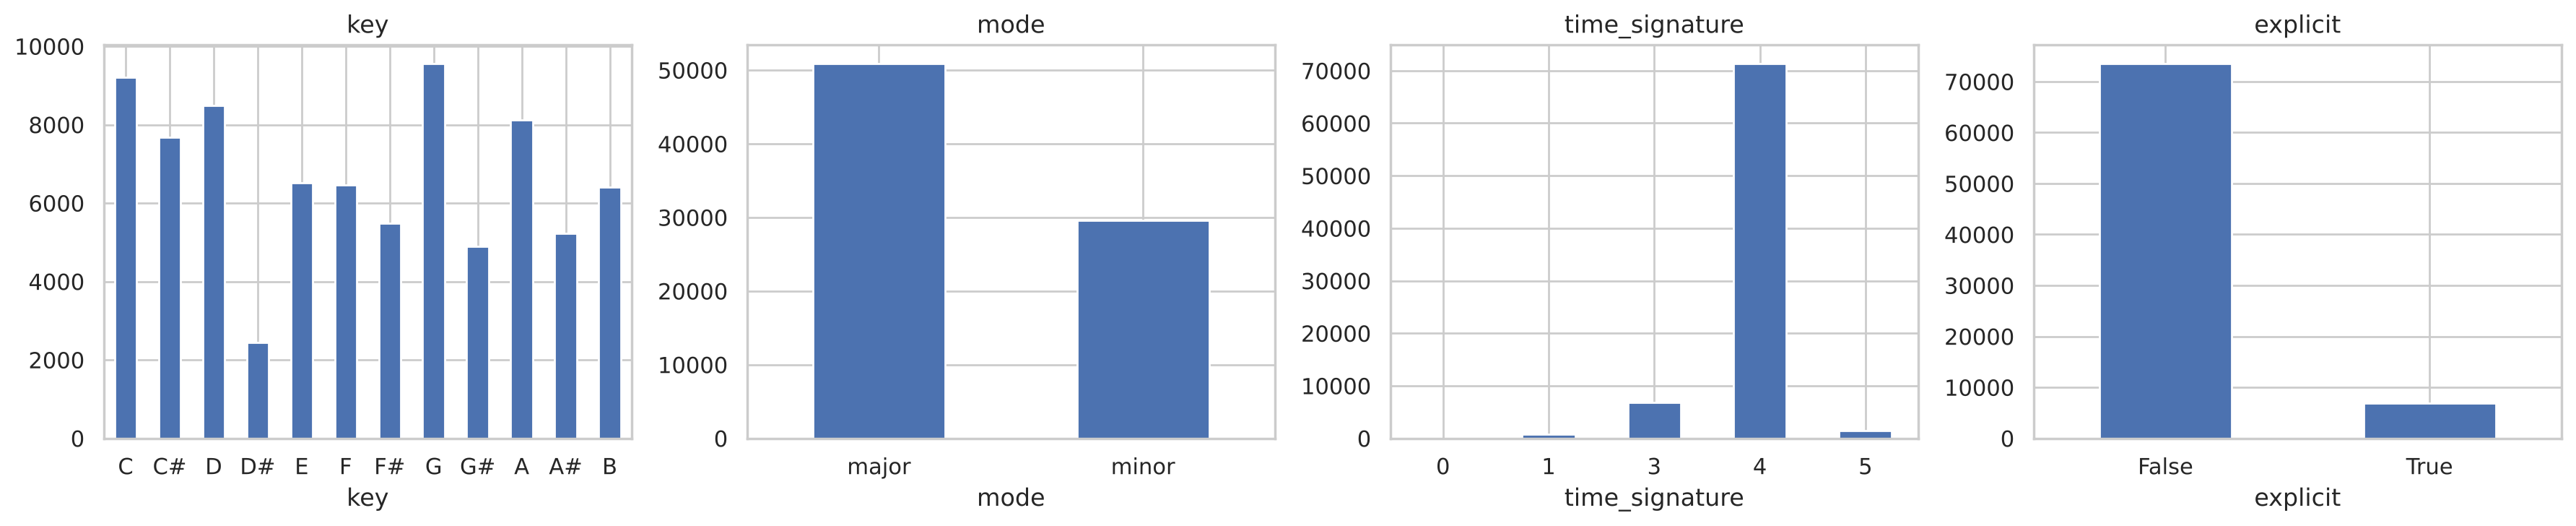

time_signature share:
 time_signature
4   0.887
3   0.085
5   0.018
1   0.010
0   0.000
Name: proportion, dtype: float64


In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
names = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
df["key"].map(dict(enumerate(names))).value_counts().reindex(names).plot.bar(ax=axes[0], title="key")
df["mode"].map({0: "minor", 1: "major"}).value_counts().plot.bar(ax=axes[1], title="mode")
df["time_signature"].value_counts().sort_index().plot.bar(ax=axes[2], title="time_signature")
df["explicit"].value_counts().plot.bar(ax=axes[3], title="explicit")
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print("time_signature share:\n", df["time_signature"].value_counts(normalize=True).round(3))

C -> G: naive |diff| =  7, circle-of-fifths distance = 0.52
C -> B: naive |diff| = 11, circle-of-fifths distance = 1.93
C -> F#: naive |diff| =  6, circle-of-fifths distance = 2.00


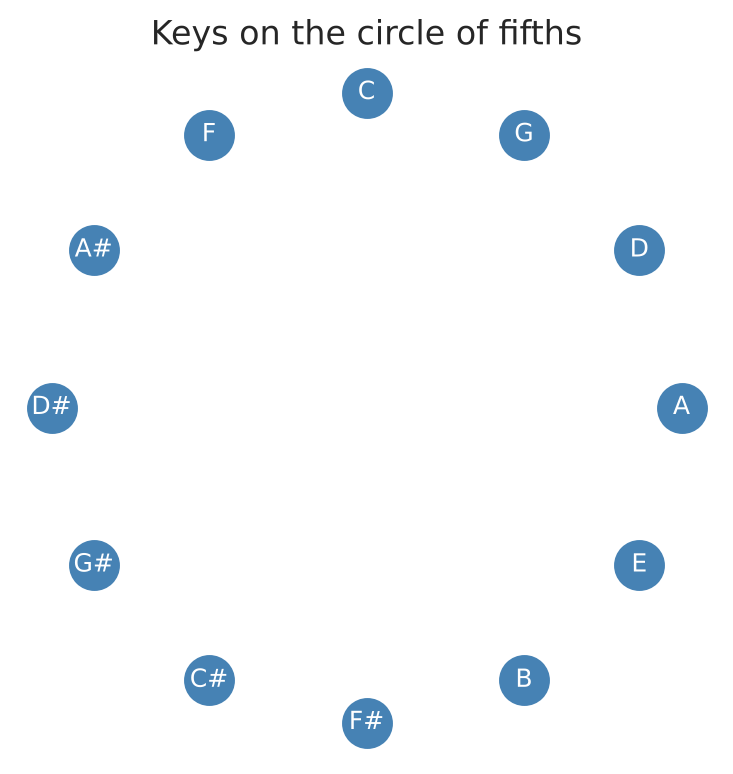

In [26]:
fifths = (7 * df["key"]) % 12
df_key = pd.DataFrame({
    "key_sin": np.sin(2 * np.pi * fifths / 12),
    "key_cos": np.cos(2 * np.pi * fifths / 12),
})

# Check: distances between keys on the circle of fifths
pos = lambda k: np.array([np.sin(2*np.pi*((7*k) % 12)/12), np.cos(2*np.pi*((7*k) % 12)/12)])
for a, b in [(0, 7), (0, 11), (0, 6)]:
    print(f"{names[a]} -> {names[b]}: naive |diff| = {abs(a-b):2d}, circle-of-fifths distance = {np.linalg.norm(pos(a)-pos(b)):.2f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
for k in range(12):
    p = pos(k); ax.scatter(*p, s=300, c="steelblue"); ax.text(*p, names[k], ha="center", va="center", color="white", fontsize=9)
ax.set_aspect("equal"); ax.axis("off"); ax.set_title("Keys on the circle of fifths"); plt.show()

**Genre as multi-hot.** Each song keeps all its genres. Multi-hot vectors let cosine reward shared genres:

$$\cos(\mathbf{g}_x, \mathbf{g}_y) = \frac{|G_x \cap G_y|}{\sqrt{|G_x|\,|G_y|}}$$

In [27]:
mlb = MultiLabelBinarizer()
G = pd.DataFrame(mlb.fit_transform(df["genres"]), columns=[f"g_{c}" for c in mlb.classes_], index=df.index)
print("Genre matrix:", G.shape, "| avg genres per song:", G.sum(1).mean().round(2))

co_arr = G.values.T @ G.values
co = pd.DataFrame(np.triu(co_arr, k=1), index=mlb.classes_, columns=mlb.classes_)   # upper triangle: each pair once
top_pairs = co.stack().sort_values(ascending=False).head(10)
print("\nMost frequent genre co-occurrences (songs sharing both):")
print(top_pairs)

Genre matrix: (80472, 114) | avg genres per song: 1.23



Most frequent genre co-occurrences (songs sharing both):
singer-songwriter  songwriter     785
dub                dubstep        677
punk               punk-rock      547
indie              indie-pop      461
reggae             reggaeton      429
alt-rock           alternative    426
latino             reggaeton      424
edm                house          395
latino             reggae         323
minimal-techno     techno         316
dtype: int64


## 8. Popularity — for re-ranking, not similarity

Popularity says nothing about how a song *sounds*, so it stays out of the similarity vector. It's useful for re-ranking and cold start:

$$\text{score}(j) = \cos(\mathbf{u}, \mathbf{x}_j) + \lambda \cdot \frac{\text{pop}_j}{100}$$

Songs with popularity == 0: 5.9%


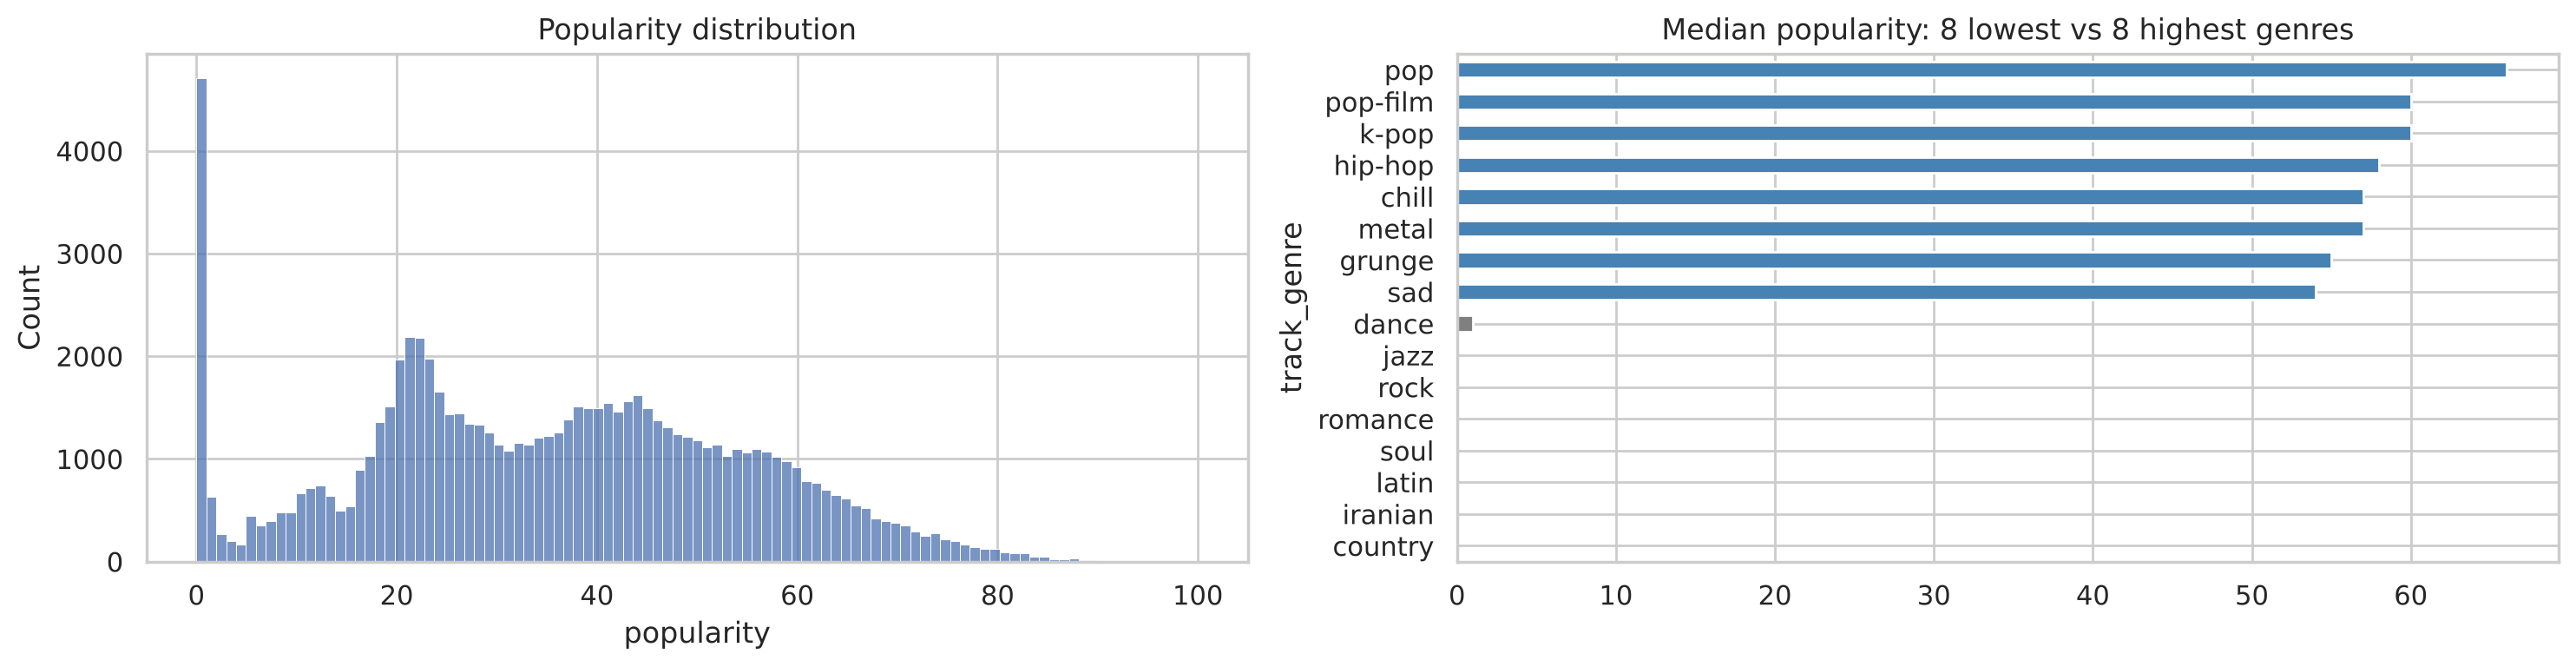

In [28]:
print(f"Songs with popularity == 0: {(df.popularity == 0).mean():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(df["popularity"], bins=101, ax=axes[0]); axes[0].set_title("Popularity distribution")
gp = raw_ok.groupby("track_genre")["popularity"].median().sort_values()
pd.concat([gp.head(8), gp.tail(8)]).plot.barh(ax=axes[1], color=["grey"] * 8 + ["steelblue"] * 8)
axes[1].set_title("Median popularity: 8 lowest vs 8 highest genres")
plt.tight_layout(); plt.show()

In [29]:
# Does popularity correlate with any audio feature? (if strongly, it would leak into similarity)
print(df[AUDIO + ["popularity"]].corr(method="spearman")["popularity"].drop("popularity").sort_values().round(3))

instrumentalness   -0.194
speechiness        -0.092
energy             -0.035
duration_ms        -0.030
liveness           -0.028
tempo              -0.000
valence             0.022
acousticness        0.027
danceability        0.085
loudness            0.095
Name: popularity, dtype: float64


## 9. Visual sanity checks

If songs of the same genre cluster in feature space, the space captures similarity. The **silhouette score** quantifies this:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$$

where $a(i)$ = mean distance to songs in the same genre, $b(i)$ = mean distance to the nearest other genre. Range −1…1; > 0 means songs are closer to their own genre.

In [30]:
# Build the weighted, scaled audio block (used again in section 10)
audio_cols = list(T.columns)
weights_map = f_tbl["weight (F / max F)"].to_dict()
src_of = {"duration_log": "duration_ms", "speechiness_log": "speechiness", "liveness_log": "liveness",
          "is_instrumental": "instrumentalness", "is_spoken": "speechiness"}
w = np.array([weights_map.get(src_of.get(c, c), 0.5) for c in audio_cols])

scaler = StandardScaler().fit(T)
A = scaler.transform(T) * np.sqrt(w)     # sqrt(w): weighted Euclidean = Euclidean on sqrt(w)*x
print(pd.Series(w, index=audio_cols).round(2).sort_values(ascending=False))

acousticness       1.000
energy             0.870
instrumentalness   0.860
is_instrumental    0.860
loudness           0.850
is_spoken          0.830
speechiness_log    0.830
danceability       0.720
valence            0.450
duration_log       0.210
liveness_log       0.190
tempo              0.090
dtype: float64


In [31]:
single = df[df["genres"].str.len() == 1]
pick = ["classical", "metal", "hip-hop", "edm", "acoustic", "jazz", "ambient", "reggaeton", "comedy", "country"]
sel = single[single["primary_genre"].isin(pick)].groupby("primary_genre").head(400)
idx = sel.index.values

for name, M in [("unweighted z-score", scaler.transform(T)), ("F-weighted", A)]:
    s = silhouette_score(M[idx], sel["primary_genre"], sample_size=min(3000, len(idx)), random_state=0)
    print(f"Silhouette by genre ({name}): {s:.3f}")

Silhouette by genre (unweighted z-score): -0.007


Silhouette by genre (F-weighted): -0.019


**Reading the score:** a silhouette near 0 means genres overlap heavily in pure audio space — a calm pop ballad and an acoustic folk song genuinely sound alike. That's fine for "sounds like" recommendations, but it's the reason section 10 also adds the **genre multi-hot block**: audio features alone won't keep recommendations inside a style.

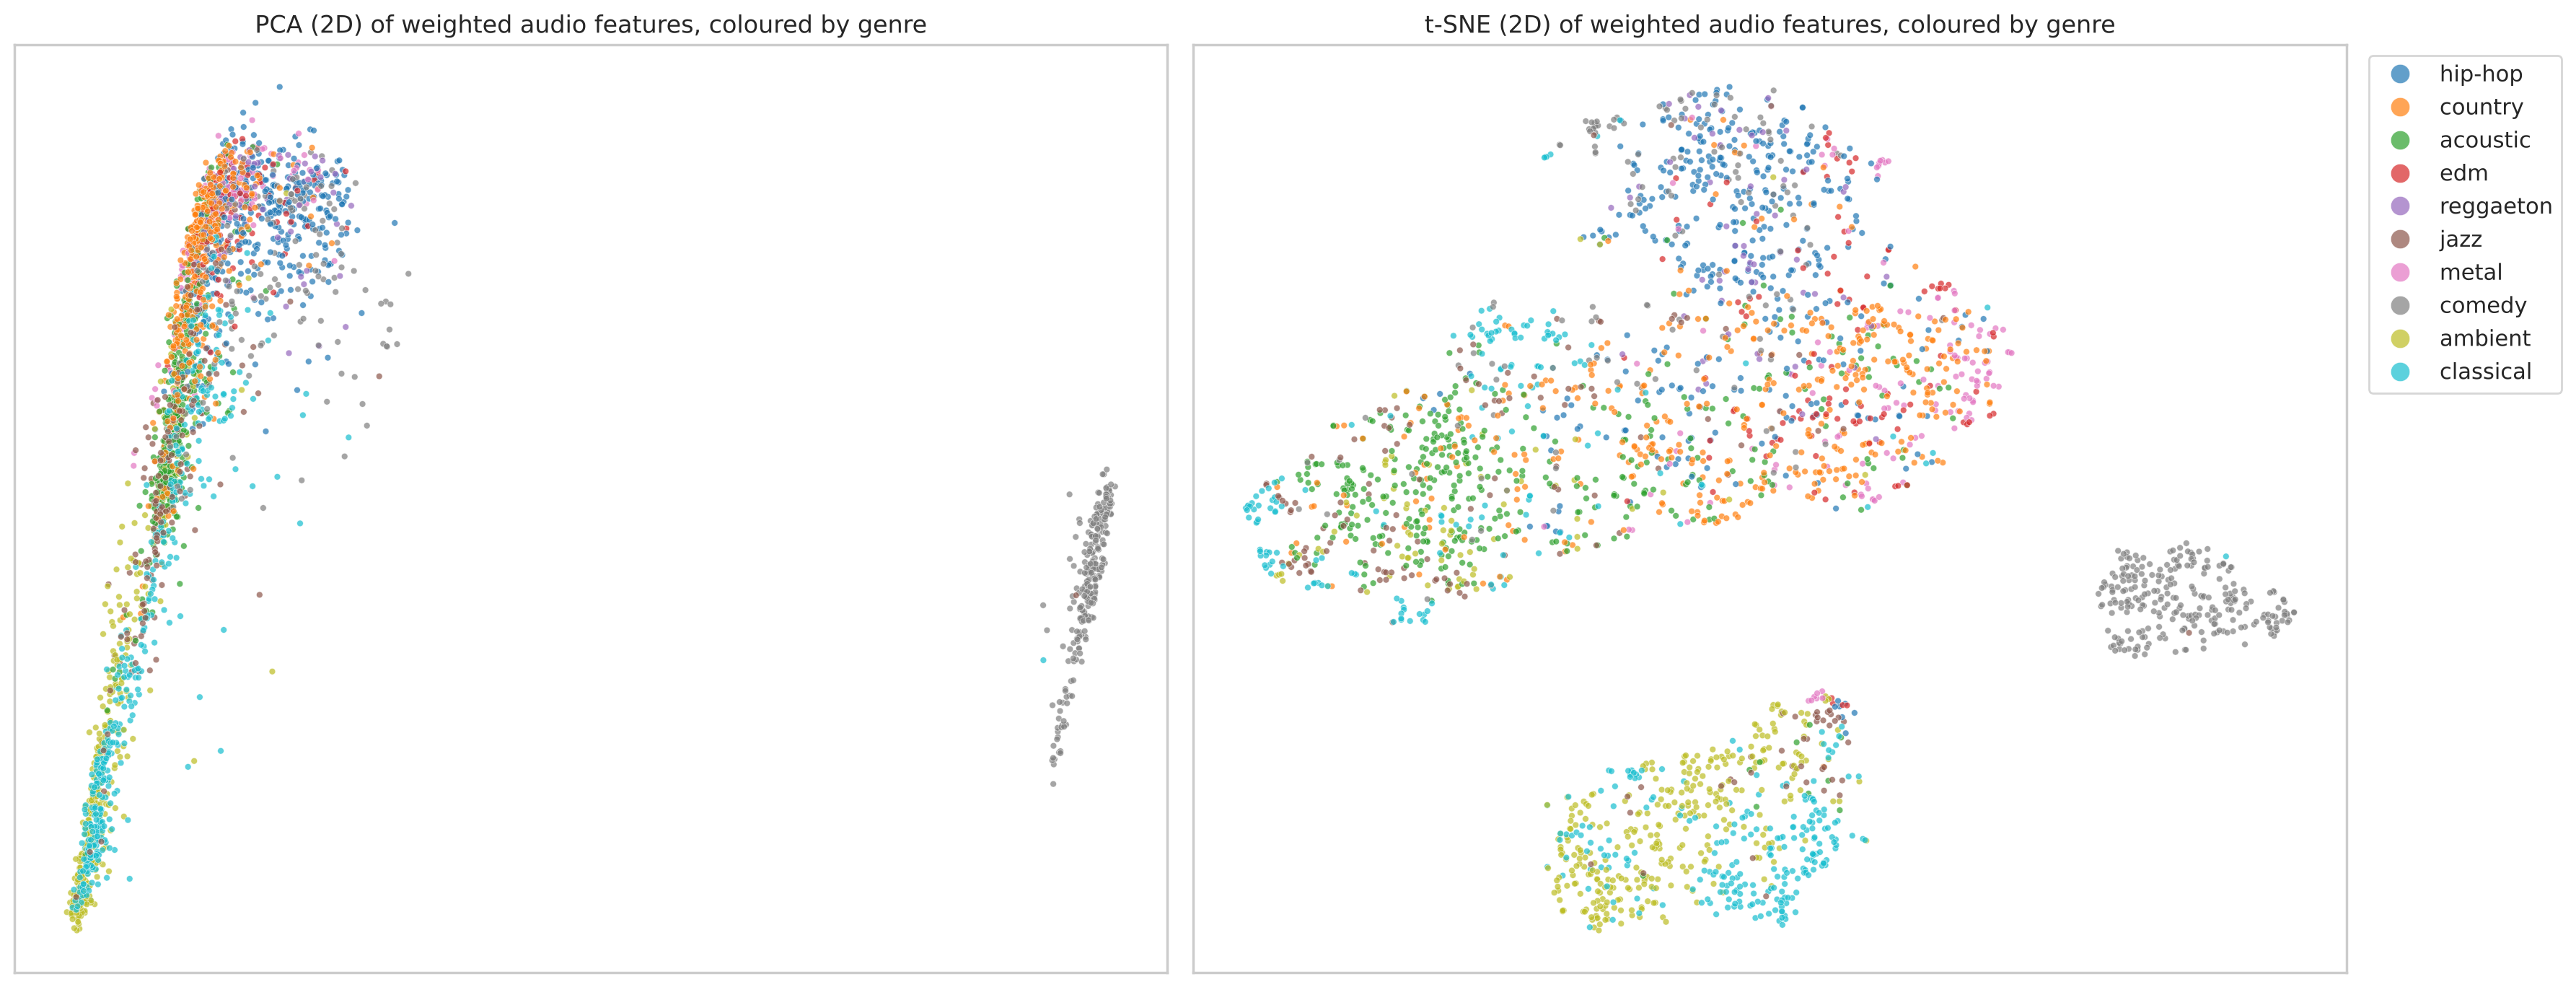

In [32]:
pc2 = PCA(2).fit_transform(A[idx])
ts2 = TSNE(2, perplexity=40, init="pca", random_state=0).fit_transform(A[idx])

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, emb, title in [(axes[0], pc2, "PCA (2D)"), (axes[1], ts2, "t-SNE (2D)")]:
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=sel["primary_genre"].values, s=10, alpha=0.7, ax=ax, palette="tab10")
    ax.set_title(f"{title} of weighted audio features, coloured by genre"); ax.set_xticks([]); ax.set_yticks([])
axes[0].get_legend().remove(); axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", markerscale=3)
plt.tight_layout(); plt.show()

Optional: `pip install umap-learn` and swap t-SNE for `umap.UMAP(n_neighbors=30).fit_transform(A[idx])` — faster, and it preserves global structure better.

## 10. Final feature matrix + content-based recommender

Final song vector = [weighted, scaled audio block | key circle | mode | explicit | genre multi-hot × α]. α controls how much genre counts relative to sound. Then cosine nearest neighbours.

In [33]:
ALPHA_GENRE = 0.6   # tune: 0 = sound only, higher = stick closer to genre
BETA_KEY = 0.3      # key/mode matter, but much less than timbre/energy

extra = pd.concat([df_key * BETA_KEY,
                   df[["mode"]].astype(float) * BETA_KEY,
                   df[["explicit"]].astype(float) * 0.3], axis=1)
G_scaled = G.values / np.sqrt(G.sum(1).values[:, None]) * ALPHA_GENRE   # unit-norm genre block, then scale

X_final = np.hstack([A, extra.values, G_scaled]).astype(np.float32)
print("Final feature matrix:", X_final.shape)

nn = NearestNeighbors(n_neighbors=11, metric="cosine").fit(X_final)

Final feature matrix: (80472, 130)


In [34]:
def recommend(query, k=10, pop_lambda=0.05):
    hits = df[df["track_name"].str.contains(query, case=False, na=False)]
    if hits.empty:
        print("No match for", query); return None
    i = hits["popularity"].idxmax()
    dist, nbr = nn.kneighbors(X_final[i:i+1], n_neighbors=k * 3 + 1)
    out = df.loc[nbr[0][1:], ["track_name", "artists", "genres", "popularity"]].copy()
    out["similarity"] = 1 - dist[0][1:]
    out["score"] = out["similarity"] + pop_lambda * out["popularity"] / 100   # popularity re-rank
    seed = df.loc[i]
    print(f"Seed: {seed.track_name} — {seed.artists}  {seed.genres}")
    return out.sort_values("score", ascending=False).head(k).reset_index(drop=True)

recommend("Bohemian Rhapsody")

Seed: Bohemian Rhapsody - Remastered 2011 — Queen  ['rock']


,track_name,artists,genres,popularity,similarity,score
0,Me Rendo,Trazendo a Arca,[groove],30,0.860,0.875
1,The End,The Doors,[psych-rock],61,0.837,0.867
2,The Rain Song - Remaster,Led Zeppelin,[hard-rock],60,0.829,0.859
3,Stairway to Heaven - Remaster,Led Zeppelin,"[hard-rock, rock]",79,0.819,0.858
4,"10,000 Reasons (Bless The Lord)",Gateway Worship,[world-music],41,0.835,0.856
5,Puisque tu pars - Live Un tour ensemble 2002,Jean-Jacques Goldman,[french],32,0.837,0.853
6,Infatuation,SOPHIE,[club],38,0.832,0.851
7,Tu Jane Na (lofi),Rudra,[indian],52,0.822,0.848
8,Wake Up,Mad Season,[grunge],53,0.820,0.846
9,Poles Apart,Pink Floyd,[psych-rock],54,0.815,0.842


In [35]:
recommend("Shape of You")

Seed: Shape of You — Ed Sheeran  ['pop']


,track_name,artists,genres,popularity,similarity,score
0,Kya Baat Ay,Harrdy Sandhu,[pop],68,0.923,0.957
1,Libaas,Kaka,[pop],65,0.913,0.945
2,There's Nothing Holdin' Me Back,Shawn Mendes,"[dance, pop]",86,0.890,0.933
3,"Naah Goriye (From ""Bala"")",B Praak;Harrdy Sandhu;Swasti Mehul,[pop],64,0.893,0.925
4,On the Low,Burna Boy,"[dance, dancehall, hip-hop]",74,0.877,0.914
5,hello hello!,Yxngxr1,"[chill, sad]",58,0.881,0.910
6,Juice,Ycee;Maleek Berry,[dancehall],49,0.884,0.908
7,Tauba (feat. Badshah),Payal Dev;Badshah,[pop],68,0.874,0.908
8,Saudade Dela e Ela Deu,Alemão Do Forró;Gino & Geno,[forro],41,0.887,0.907
9,Pull Up,Timaya;Burna Boy,[dancehall],53,0.880,0.907


In [36]:
recommend("Clair de Lune")

Seed: Clair de Lune, L. 32 — Claude Debussy;Martin Jones  ['classical']


,track_name,artists,genres,popularity,similarity,score
0,"Nocturne No. 2 in E-Flat Major, Op. 9 No. 2",Frédéric Chopin;Daniel Barenboim,[classical],67,0.994,1.027
1,Gnossienne No. 1,Erik Satie;Alena Cherny,[classical],66,0.992,1.025
2,Wind Song,Ludovico Einaudi,"[ambient, classical]",65,0.991,1.024
3,Fracture,Stephan Moccio,"[ambient, classical, piano]",69,0.986,1.021
4,"Deux Arabesques, L66: No. 1: Andantino con moto",Claude Debussy;Kathryn Stott,[classical],45,0.994,1.017
5,"Fantaisie-Impromptu In C-Sharp Minor, Op. 66",Frédéric Chopin;Daniil Trifonov,[classical],40,0.992,1.012
6,"Préludes / Book 1, L. 117: 8. La fille aux che...",Claude Debussy;Jean-Rodolphe Kars,[classical],50,0.985,1.010
7,Finale/Reprise,Chantry Johnson,"[disney, piano]",29,0.986,1.001
8,"Suite bergamasque, L. 75: III. Clair de lune",Claude Debussy;Alice Sara Ott,[classical],0,0.999,0.999
9,"Berceuse in D-Flat Major, Op. 57",Frédéric Chopin;Wilhelm Kempff,[classical],0,0.995,0.995


In [37]:
# Save artefacts for the app
import joblib, os
os.makedirs("artifacts", exist_ok=True)
np.save("artifacts/X_final.npy", X_final)
df[["track_id", "track_name", "artists", "album_name", "genres", "popularity"]].to_pickle("artifacts/catalogue.pkl")
joblib.dump({"scaler": scaler, "weights": w, "audio_cols": audio_cols, "mlb": mlb,
             "ALPHA_GENRE": ALPHA_GENRE, "BETA_KEY": BETA_KEY}, "artifacts/preprocess.joblib")
print("Saved to ./artifacts")

Saved to ./artifacts


## 11. Plugging in implicit ratings (preview)

Once the Spotify-like UI logs events, each (user, track) pair gets an implicit rating $r_{uj}$. A simple scheme:

| Event | Signal |
|---|---|
| full listen (≥ 80%) | +1.0 |
| like / add to playlist | +2.0 |
| repeat | +1.5 |
| skip < 30 s | −1.0 |

$$r_{uj} = \sum_{e \in \text{events}(u,j)} w_e, \qquad \mathbf{u} = \frac{\sum_j r_{uj}\,\mathbf{x}_j}{\sum_j |r_{uj}|}, \qquad \text{recommend } \arg\max_j \cos(\mathbf{u}, \mathbf{x}_j)$$

Negative ratings push the profile away from disliked songs. This only works if the $\mathbf{x}_j$ live in the clean, scaled, weighted space built above.

In [38]:
EVENT_W = {"full_listen": 1.0, "like": 2.0, "repeat": 1.5, "skip": -1.0}

def find(q):
    h = df[df["track_name"].str.contains(q, case=False, na=False)]
    return h["popularity"].idxmax()

# Simulated event log for one user
log = pd.DataFrame([
    (find("Bohemian Rhapsody"), "full_listen"), (find("Bohemian Rhapsody"), "like"),
    (find("Stairway to Heaven"), "full_listen"), (find("Stairway to Heaven"), "repeat"),
    (find("Hotel California"), "full_listen"),
    (find("Shape of You"), "skip"),
], columns=["item", "event"])
log["w"] = log["event"].map(EVENT_W)
ratings = log.groupby("item")["w"].sum()
print("Implicit ratings:\n", ratings.rename(index=df["track_name"]))

u = (ratings.values[:, None] * X_final[ratings.index]).sum(0) / np.abs(ratings.values).sum()
dist, nbr = nn.kneighbors(u[None, :], n_neighbors=30)
recs = df.loc[nbr[0], ["track_name", "artists", "genres", "popularity"]].assign(similarity=1 - dist[0])
recs[~recs.index.isin(ratings.index)].head(10).reset_index(drop=True)

Implicit ratings:
 item
Shape of You                          -1.000
Hotel California - 2013 Remaster       1.000
Bohemian Rhapsody - Remastered 2011    3.000
Stairway to Heaven - Remaster          2.500
Name: w, dtype: float64


,track_name,artists,genres,popularity,similarity
0,Me Rendo,Trazendo a Arca,[groove],30,0.929
1,The Rain Song - Remaster,Led Zeppelin,[hard-rock],60,0.926
2,The End,The Doors,[psych-rock],61,0.903
3,Release,Pearl Jam,[grunge],55,0.902
4,Dekho Manashi,Fossils,[folk],32,0.893
5,Babe I'm Gonna Leave You - 1990 Remaster,Led Zeppelin,[hard-rock],62,0.889
6,"10,000 Reasons (Bless The Lord)",Gateway Worship,[world-music],41,0.887
7,Wake Up,Mad Season,[grunge],53,0.878
8,Secret Place - Live,Hillsong Worship;Chris Davenport,[world-music],37,0.877
9,Eu Tenho Um Pai,Casa Worship;Ricardinho;MOVER,[gospel],40,0.875
